In [1]:
#!/usr/bin/env python3
"""
==============================================================================
HAOR VALIDATION ROUND 2: NEXT CHECKS  (haor_next_checks.ipynb)
==============================================================================
Lives in /work/a06/wasif/haor_validation_package/ and runs on the server only.
Open it in Jupyter and run all cells (about 20 minutes; N4 is the slow one).

Reads   /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/
Writes  /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/next_checks/
        Everything this notebook makes goes there, including run_log.txt (every
        printed line) and the round-2 cards. Download that one folder for Claude.

  N1  SWOT step test against every radar view (100 m, by-pass, 30 m, and the
      by-orbit stacks once they exist)
  N2  SWOT coupling and decoupling dates against the radar's merge dates
  N3  Why the 30 m run breaks the merges
  N4  The 30 m result with other bridge settings and coarser pixels
  N5  Per-haor SWOT levels, drawdown order, distance control for S5
  N6  The blind cards: why round 1 failed, the round-2 cards, and their score
  N7  Adjacency tolerance
  N9  The two families of Sentinel-1 passes (named by orbit once
      s1_pass_catalog.csv exists)
  N10 Sentinel-2 on the clear key dates
  N11 Does one baseline per orbit fix the pass-family gap? (by-orbit stacks)
  N8  Scorecard, and a copy of the by-orbit label tables into next_checks/

Every cell skips with a message when its input is not there yet, so the
notebook can be run after each step and simply does more each time.
==============================================================================
"""
import os, sys, glob, re, datetime, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.lines, matplotlib.patches
import matplotlib.pyplot as plt
from scipy import ndimage
import rasterio
warnings.filterwarnings("ignore", category=RuntimeWarning)
print("✓ imports ok")

✓ imports ok


In [2]:
# ============================ PATHS & SETTINGS ============================
CODE_DIR  = "/work/a06/wasif/haor_validation_package"         # this notebook, haor_validation_core.py
VAL       = "/work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation"
HAORS_SHP = "/work/a06/wasif/haor_flood_analysis/digitization/haors_manual.shp"
OUT       = os.path.join(VAL, "next_checks")                   # every output of this notebook
FIGS      = os.path.join(OUT, "figs")
os.makedirs(FIGS, exist_ok=True)

# every print() below also goes to next_checks/run_log.txt, so the results travel with the folder
import builtins
_LOG = open(os.path.join(OUT, "run_log.txt"), "w")
def print(*args, **kw):
    builtins.print(*args, **kw)
    if kw.get("file") is None and not _LOG.closed:
        builtins.print(*args, **{k: v for k, v in kw.items() if k in ("sep", "end")}, file=_LOG)
        _LOG.flush()
print(f"run started {datetime.datetime.now():%Y-%m-%d %H:%M}")

VIEWS = {   # radar views compared with SWOT: name -> folder of label outputs
    "100 m": os.path.join(VAL, "labels"),
    "100 m by-pass": os.path.join(VAL, "labels_hires_haor_flood_by_pass_100m_physical"),
    "30 m": os.path.join(VAL, "labels_hires_haor_flood_pooled_30m_physical"),
}
# the round-2 by-orbit stacks join automatically once haor_validation_labels.py has run on them
BYORBIT = {"100 m by-orbit (mask)": "haor_flood_byorbit_100m",
           "100 m by-orbit (clamp)": "haor_flood_byorbit_100m_clamp"}
for _name, _stack in BYORBIT.items():
    _f = os.path.join(VAL, f"labels_hires_{_stack}_physical")
    if os.path.isdir(_f) and glob.glob(os.path.join(_f, "matrix_recomputed_*.csv")):
        VIEWS[_name] = _f
print("radar views found: " + ", ".join(v for v, f in VIEWS.items() if os.path.isdir(f)))
REF, FINE = "100 m", "30 m"
STEPS_CSV = os.path.join(VAL, "swot", "boundary_steps.csv")
PIX_DIR   = os.path.join(VAL, "swot_pixels_all")
CAT       = os.path.join(OUT, "s1_pass_catalog.csv")            # written by haor_s1_pass_catalog.py

HAOR_IDS = ["MTN", "SHN", "HLR", "TGR", "GMA"]
ADJ      = ["SHN-GMA", "HLR-GMA"]       # replaced below by validation/adjacency.csv when it exists
WET         = 0.6    # cluster flooded fraction that makes a pass "wet" (same as S4)
COUPLED_M   = 0.05   # |step| below this = one level, within SWOT noise
DECOUPLED_M = 0.10   # |step| above this AND bootstrap CI excluding 0 = two levels
CONTACT_M   = 300    # contact zone width, same as haor_validation_labels.py
N_PERM      = 5000
UTM         = "EPSG:32646"
HAOR_COLORS = {"GMA": "#E07856", "TGR": "#1C7293", "HLR": "#0F766E", "SHN": "#7C3AED", "MTN": "#0A2540"}

# pixel classes in codes_<year>.tif (haor_validation_core.py)
C_OUT, C_DRY, C_WET, C_WETFILL, C_DROP, C_DRYFILL, C_NODATA, C_SKIP = 0, 1, 2, 3, 4, 5, 6, 255

sys.path.insert(0, CODE_DIR)
try:
    import haor_validation_core as core
    print("✓ haor_validation_core found")
except ImportError:
    core = None
    print(f"haor_validation_core.py not found in {CODE_DIR}: N4 and N7 will be skipped")

haors = None
if HAORS_SHP and os.path.exists(HAORS_SHP):
    import geopandas as gpd
    os.environ["SHAPE_RESTORE_SHX"] = "YES"
    haors = gpd.read_file(HAORS_SHP)
    haors = haors[haors["haor_id"] != "DUMMY"].copy()
    if (~haors.geometry.is_valid).any():
        haors["geometry"] = haors.geometry.buffer(0)
    print(f"✓ shapefile: {len(haors)} haors")
else:
    print(f"shapefile not found at {HAORS_SHP}: cells that need haor outlines will skip")


def dayidx(desc, base_year):
    m = re.search(r"(20\d{2})(\d{2})(\d{2})", desc or "")
    if not m:
        return np.nan
    y, mo, d = map(int, m.groups())
    return float((datetime.date(y, mo, d) - datetime.date(base_year, 1, 1)).days)


def doy_to_date(year, doy):
    return datetime.date(int(year), 1, 1) + datetime.timedelta(days=float(doy))


def load_view(folder):
    """{year: matrix of dominant body labels, indexed by day} for one radar view."""
    out = {}
    for f in sorted(glob.glob(os.path.join(folder, "matrix_recomputed_*.csv"))):
        y = int(re.search(r"(\d{4})", os.path.basename(f)).group(1))
        out[y] = pd.read_csv(f).set_index("doy").sort_index()
    return out


if os.path.exists(os.path.join(VAL, "adjacency.csv")):
    _a = pd.read_csv(os.path.join(VAL, "adjacency.csv"))
    ADJ = _a.loc[_a.adjacent.astype(str).str.lower() == "true", "pair"].tolist()
print(f"adjacent pairs: {ADJ}")

MATS = {v: load_view(f) for v, f in VIEWS.items() if os.path.isdir(f)}
for v, m in MATS.items():
    print(f"  {v:15s} years {sorted(m)}")


def pair_state(view, year, doy, pair, tol=1.0):
    """merged / separate / no water / skipped, or None when the view has no date
    within tol days."""
    m = MATS.get(view, {}).get(int(year))
    if m is None or not len(m):
        return None
    k = np.abs(m.index.values - doy)
    if k.min() > tol:
        return None
    row = m.iloc[int(k.argmin())]
    a, b = pair.split("-")
    if row[a] < 0 or row[b] < 0:
        return "skipped"
    if row[a] == 0 or row[b] == 0:
        return "no water"
    return "merged" if row[a] == row[b] else "separate"


def perm_test(g, col, n=N_PERM, seed=2):
    """One-sided: median |step| larger when `col` says separate than when merged.
    Labels are shuffled WITHIN each pair, as in S4."""
    rng = np.random.default_rng(seed)
    g = g[g[col].isin(["merged", "separate"])]
    v = g.abs_step.values
    lab = (g[col] == "separate").values
    if lab.sum() < 3 or (~lab).sum() < 3:
        return np.nan, np.nan
    grp = [np.where(g.pair.values == p)[0] for p in g.pair.unique()]
    obs = np.median(v[lab]) - np.median(v[~lab])
    cnt, perm = 0, lab.copy()
    for _ in range(n):
        for ix in grp:
            perm[ix] = rng.permutation(lab[ix])
        if perm.all() or (~perm).all():
            continue
        cnt += (np.median(v[perm]) - np.median(v[~perm])) >= obs
    return obs, (cnt + 1) / (n + 1)


SCORE = []   # (check, criterion, result) rows for N8
print("✓ settings and helpers ready")

run started 2026-10-19 15:17
radar views found: 100 m, 100 m by-pass, 30 m, 100 m by-orbit (mask), 100 m by-orbit (clamp)
✓ haor_validation_core found
✓ shapefile: 5 haors
adjacent pairs: ['SHN-GMA', 'HLR-GMA']
  100 m           years [2019, 2020, 2021, 2022, 2023, 2024, 2025]
  100 m by-pass   years [2019, 2020, 2021, 2022, 2023, 2024, 2025]
  30 m            years [2023, 2024, 2025]
  100 m by-orbit (mask) years [2019, 2020, 2021, 2022, 2023, 2024, 2025]
  100 m by-orbit (clamp) years [2019, 2020, 2021, 2022, 2023, 2024, 2025]
✓ settings and helpers ready


171 pair-pass steps; matched to a date in each view:
100 m                     171
100 m by-pass             171
30 m                      171
100 m by-orbit (mask)     171
100 m by-orbit (clamp)    171

=== median |step| (m) by radar view ===
                  view      scope  n_merged  n_separate  med_step_merged  med_step_separate  med_placebo  p_separate_gt_merged
                 100 m all passes        40         102            0.032              0.045        0.020              0.027395
                 100 m wet passes        37          27            0.032              0.021        0.019              0.904619
         100 m by-pass all passes        40         103            0.033              0.044        0.020              0.034793
         100 m by-pass wet passes        36          28            0.032              0.020        0.019              0.935613
                  30 m all passes         2         121            0.021              0.036        0.019                 

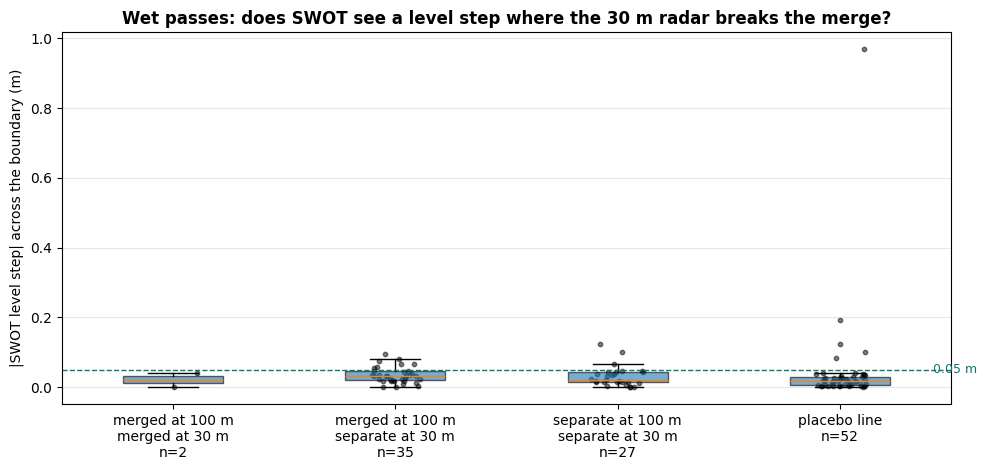

In [3]:
# ============ N1: THE SWOT STEP TEST AGAINST THREE RADAR VIEWS ============
# Round 1 result: on wet passes SWOT sees no level step across either shared
# boundary, whatever the 100 m radar says (merged 0.032 m, separate 0.021 m,
# placebo 0.019 m). This cell asks the same question of the other two radar
# views, and asks the question that decides what the 30 m result means:
#   on passes where 100 m says MERGED but 30 m says SEPARATE, is there a step?
# Pre-stated reading:
#   steps on those passes no larger than about 2 x placebo -> the 30 m breaks
#   are not level barriers (a narrow dry feature, vegetation or speckle that
#   water passes around or over), so 30 m contiguity is not a hydraulic measure
#   steps clearly larger (and CI excluding 0) -> the 30 m breaks are real
#   barriers and the 100 m merges hide them (the levee problem)
ST = pd.read_csv(STEPS_CSV)
ST["wet"] = ST.cluster_frac >= WET
for v in MATS:
    ST[v] = [pair_state(v, r.year, r.doy, r.pair) for r in ST.itertuples()]
print(f"{len(ST)} pair-pass steps; matched to a date in each view:")
print(ST[list(MATS)].notna().sum().to_string())

rows = []
for v in MATS:
    for scope, g in [("all passes", ST), ("wet passes", ST[ST.wet])]:
        g = g[g[v].isin(["merged", "separate"])]
        x = g.loc[g[v] == "merged", "abs_step"]
        y = g.loc[g[v] == "separate", "abs_step"]
        d, p = perm_test(g, v)
        rows.append(dict(view=v, scope=scope, n_merged=len(x), n_separate=len(y),
                         med_step_merged=round(x.median(), 3) if len(x) else np.nan,
                         med_step_separate=round(y.median(), 3) if len(y) else np.nan,
                         med_placebo=round(g.abs_placebo.median(), 3), p_separate_gt_merged=p))
N1 = pd.DataFrame(rows)
print("\n=== median |step| (m) by radar view ===")
print(N1.to_string(index=False))
N1.to_csv(os.path.join(OUT, "N1_step_by_view.csv"), index=False)

if REF in MATS and FINE in MATS:
    W = ST[ST.wet & ST[REF].isin(["merged", "separate"]) & ST[FINE].isin(["merged", "separate"])].copy()
    W["combo"] = W[REF] + " at 100 m, " + W[FINE] + " at 30 m"
    tab = W.groupby("combo").agg(n=("abs_step", "size"), med_step=("abs_step", "median"),
                                 share_ci_excl_0=("ci_excludes_0", "mean"),
                                 med_placebo=("abs_placebo", "median")).round(3)
    print("\n=== wet passes, 100 m against 30 m ===")
    print(tab.to_string())
    W.to_csv(os.path.join(OUT, "N1_wet_100m_vs_30m.csv"), index=False)
    key = W[(W[REF] == "merged") & (W[FINE] == "separate")]
    plc = np.nanmedian(W.abs_placebo)
    if len(key):
        verdict = "NOT A LEVEL BARRIER" if key.abs_step.median() <= 2 * plc else "LEVEL BARRIER"
        print(f"\n100 m merged but 30 m separate: median |step| {key.abs_step.median():.3f} m "
              f"against placebo {plc:.3f} m -> {verdict}")
        SCORE.append(("30 m breaks are level barriers?", "median |step| on 100 m merged / 30 m separate passes > 2 x placebo",
                      f"{'NO' if verdict.startswith('NOT') else 'YES'} ({key.abs_step.median():.3f} m vs placebo {plc:.3f} m, n {len(key)})"))

    fig, ax = plt.subplots(figsize=(10, 4.8))
    cats = sorted(W.combo.unique())
    data = [W.loc[W.combo == c, "abs_step"].values for c in cats] + [W.abs_placebo.dropna().values]
    labels = [c.replace(", ", "\n") + f"\nn={len(d)}" for c, d in zip(cats, data[:-1])] + [f"placebo line\nn={len(data[-1])}"]
    bp = ax.boxplot(data, tick_labels=labels, showfliers=False, patch_artist=True)
    for b in bp["boxes"]:
        b.set_alpha(.6)
    for i, d in enumerate(data, 1):
        ax.scatter(np.full(len(d), i) + np.random.default_rng(i).uniform(-.12, .12, len(d)), d, s=10, c="k", alpha=.5)
    ax.axhline(COUPLED_M, color="#0F766E", ls="--", lw=1)
    ax.text(len(data) + .4, COUPLED_M, f" {COUPLED_M:.2f} m", va="center", color="#0F766E", fontsize=9)
    ax.set_ylabel("|SWOT level step| across the boundary (m)")
    ax.set_title("Wet passes: does SWOT see a level step where the 30 m radar breaks the merge?", fontweight="bold")
    ax.grid(alpha=.3, axis="y")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, "N1_step_100m_vs_30m.png"), dpi=160); plt.show()

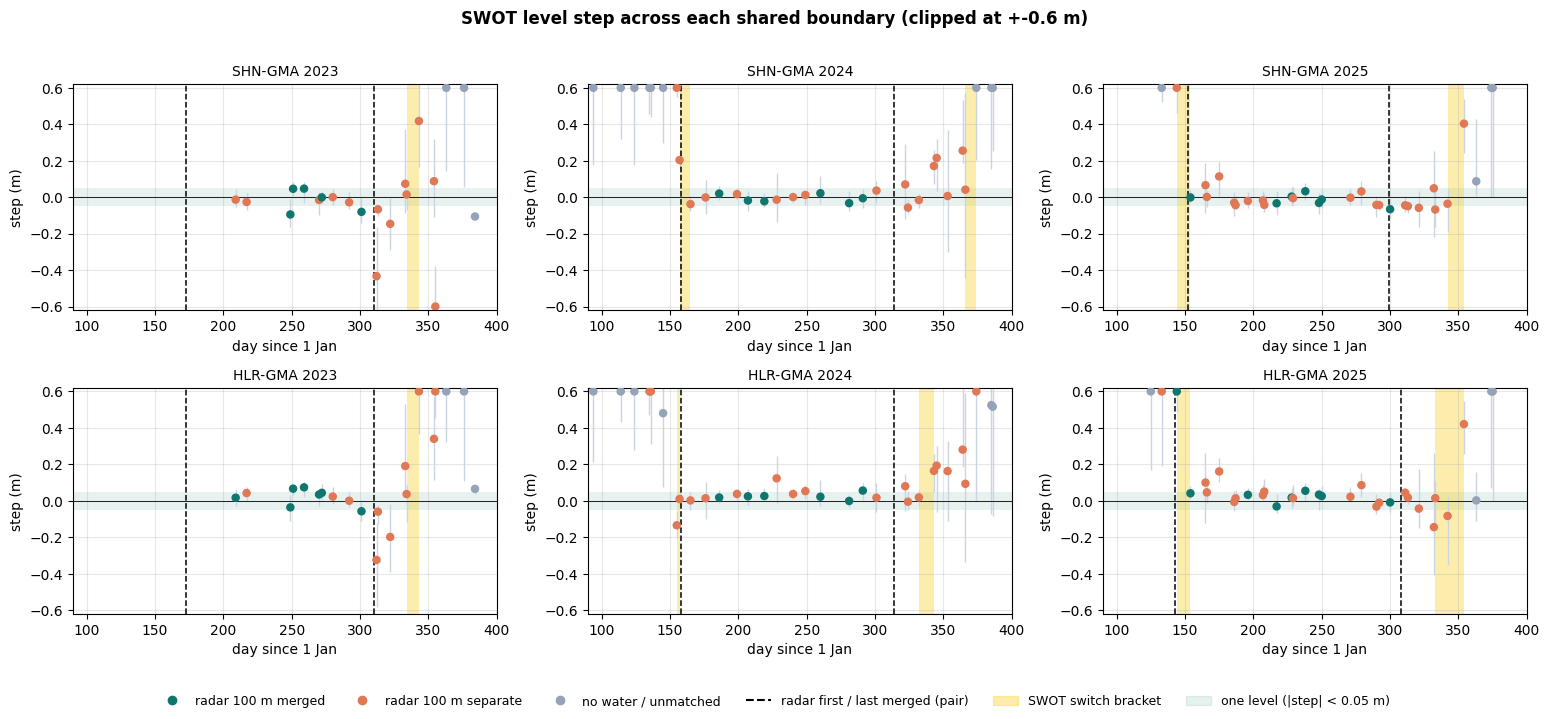

   pair  year    swot_coupling_bracket radar_first_merged  start_agrees  swot_decoupling_bracket radar_last_merged radar_last_all5_bridge0  end_agrees  radar_end_early_days
SHN-GMA  2023                   ? to ?         2023-06-23         False 2023-12-01 to 2023-12-10        2023-11-07              2023-11-07       False                  24.0
SHN-GMA  2024 2024-06-06 to 2024-06-14         2024-06-07          True 2025-01-01 to 2025-01-09        2024-11-10              2024-11-08       False                  52.0
SHN-GMA  2025 2025-05-25 to 2025-06-04         2025-06-02          True 2025-12-09 to 2025-12-21        2025-10-27              2025-11-05       False                  43.0
HLR-GMA  2023                   ? to ?         2023-06-23         False 2023-12-01 to 2023-12-10        2023-11-07              2023-11-07       False                  24.0
HLR-GMA  2024 2024-06-04 to 2024-06-06         2024-06-07          True 2024-11-28 to 2024-12-09        2024-11-10              2024-11

In [4]:
# ============ N2: WHEN DO THE HAORS SHARE ONE WATER LEVEL? SWOT AGAINST THE RADAR ============
# A level step across a shared boundary is the most direct sign that two basins
# no longer share one water surface. For every pair and year this finds:
#   COUPLING (spring)  : the last pass in days 100-170 with a two-level step
#                        (|step| > DECOUPLED_M, interval excluding 0), and the
#                        first later pass with one level (|step| < COUPLED_M)
#   DECOUPLING (autumn): the last pass in days 270-420 with one level (state not
#                        'no water'), and the first later pass with two levels
# Each gives a BRACKET (two SWOT pass dates). The true switch lies inside it.
# Compared with: the radar's first and last merged date for the pair (100 m,
# production), and the last merged date with BRIDGE = 0 (from the sensitivity
# run), which keeps water links narrower than 300 m.
def bracket(g, lo, hi, kind):
    w = g[(g.doy >= lo) & (g.doy <= hi)].sort_values("doy")
    two = (w.abs_step > DECOUPLED_M) & w.ci_excludes_0
    one = (w.abs_step < COUPLED_M) & (w.state != "no water")
    if kind == "coupling":
        if not two.any():
            return np.nan, (float(w[one].doy.iloc[0]) if one.any() else np.nan)
        t = w[two].doy.max(); after = w[(w.doy > t) & one[w.index]]
        return float(t), (float(after.doy.iloc[0]) if len(after) else np.nan)
    if not one.any():
        return np.nan, (float(w[two].doy.iloc[0]) if two.any() else np.nan)
    t = w[one].doy.max(); after = w[(w.doy > t) & two[w.index]]
    return float(t), (float(after.doy.iloc[0]) if len(after) else np.nan)

B0 = None
f0 = os.path.join(VAL, "sensitivity", "dates_BRIDGE_0.csv")
if os.path.exists(f0):
    B0 = pd.read_csv(f0)
rows = []
years = sorted(ST.year.unique())
fig, ax = plt.subplots(len(ADJ), len(years), figsize=(5.2 * len(years), 3.6 * len(ADJ)), squeeze=False)
for i, pair in enumerate(ADJ):
    aa, bb = pair.split("-")
    for j, y in enumerate(years):
        g = ST[(ST.pair == pair) & (ST.year == y)].copy()
        # day of the SWOT pass itself (ST.doy is the matched RADAR day, up to 3 days off)
        g["doy"] = (pd.to_datetime(g.date) - pd.Timestamp(f"{int(y)}-01-01")).dt.days.astype(float)
        g = g.sort_values("doy")
        a = ax[i][j]
        if not len(g):
            a.axis("off"); continue
        c0, c1 = bracket(g, 100, 170, "coupling")
        d0, d1 = bracket(g, 270, 420, "decoupling")
        m = MATS[REF].get(int(y)); rf = rl = np.nan
        if m is not None:
            mm = m[(m.index <= 430) & (m[aa] > 0) & (m[aa] == m[bb])]
            if len(mm):
                rf, rl = float(mm.index.min()), float(mm.index.max())
        b0l = np.nan
        if B0 is not None:
            q = B0[(B0.year == y) & (B0.all_connected == True) & (B0.doy <= 430)]
            b0l = float(q.doy.max()) if len(q) else np.nan
        rows.append(dict(pair=pair, year=y,
                         swot_coupling_bracket=f"{doy_to_date(y, c0) if np.isfinite(c0) else '?'} to {doy_to_date(y, c1) if np.isfinite(c1) else '?'}",
                         radar_first_merged=doy_to_date(y, rf) if np.isfinite(rf) else None,
                         swot_decoupling_bracket=f"{doy_to_date(y, d0) if np.isfinite(d0) else '?'} to {doy_to_date(y, d1) if np.isfinite(d1) else '?'}",
                         radar_last_merged=doy_to_date(y, rl) if np.isfinite(rl) else None,
                         radar_last_all5_bridge0=doy_to_date(y, b0l) if np.isfinite(b0l) else None,
                         c0=c0, c1=c1, d0=d0, d1=d1, rf=rf, rl=rl,
                         start_agrees=bool(np.isfinite(c0) and np.isfinite(c1) and np.isfinite(rf) and c0 - 3 <= rf <= c1 + 3),
                         end_agrees=bool(np.isfinite(d0) and np.isfinite(d1) and np.isfinite(rl) and d0 - 3 <= rl <= d1 + 3),
                         radar_end_early_days=(d0 - rl) if np.isfinite(d0) and np.isfinite(rl) else np.nan))
        col = g[REF].map({"merged": "#0F766E", "separate": "#E07856"}).fillna("#94A3B8")
        a.axhspan(-COUPLED_M, COUPLED_M, color="#0F766E", alpha=.10, lw=0)
        for lo, hi in [(c0, c1), (d0, d1)]:
            if np.isfinite(lo) and np.isfinite(hi):
                a.axvspan(lo, hi, color="#FACC15", alpha=.35, lw=0)
        a.errorbar(g.doy, g.step.clip(-0.6, 0.6), yerr=[(g.step - g.ci_lo).clip(0, .6), (g.ci_hi - g.step).clip(0, .6)],
                   fmt="none", ecolor="#CBD5E1", lw=1)
        a.scatter(g.doy, g.step.clip(-0.6, 0.6), c=col, s=26, zorder=3)
        a.axhline(0, color="k", lw=.6)
        for xv in [rf, rl]:
            if np.isfinite(xv):
                a.axvline(xv, color="k", ls="--", lw=1.1)
        a.set_ylim(-0.62, 0.62); a.set_xlim(90, 400)
        a.set_title(f"{pair} {y}", fontsize=10); a.set_xlabel("day since 1 Jan"); a.set_ylabel("step (m)")
        a.grid(alpha=.3)
handles = [matplotlib.lines.Line2D([], [], marker="o", ls="", color=c, label=l) for c, l in
           [("#0F766E", "radar 100 m merged"), ("#E07856", "radar 100 m separate"), ("#94A3B8", "no water / unmatched")]] + \
          [matplotlib.lines.Line2D([], [], color="k", ls="--", label="radar first / last merged (pair)"),
           matplotlib.patches.Patch(color="#FACC15", alpha=.35, label="SWOT switch bracket"),
           matplotlib.patches.Patch(color="#0F766E", alpha=.10, label=f"one level (|step| < {COUPLED_M} m)")]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, fontsize=9)
fig.suptitle("SWOT level step across each shared boundary (clipped at +-0.6 m)", fontweight="bold")
plt.tight_layout(rect=[0, 0.06, 1, 0.97]); plt.savefig(os.path.join(FIGS, "N2_coupling_timeline.png"), dpi=150); plt.show()

N2 = pd.DataFrame(rows)
print(N2[["pair", "year", "swot_coupling_bracket", "radar_first_merged", "start_agrees",
          "swot_decoupling_bracket", "radar_last_merged", "radar_last_all5_bridge0", "end_agrees", "radar_end_early_days"]]
      .to_string(index=False))
N2.to_csv(os.path.join(OUT, "N2_coupling_decoupling.csv"), index=False)
s = N2.dropna(subset=["c0", "c1", "rf"]); e = N2.dropna(subset=["d0", "d1", "rl"])
SCORE.append(("SWOT coupling date matches radar first merge", "radar first merged date inside the SWOT spring bracket (+-3 d)",
              f"{int(s.start_agrees.sum())} of {len(s)} pair-years"))
SCORE.append(("SWOT decoupling date matches radar last merge", "radar last merged date inside the SWOT autumn bracket (+-3 d)",
              f"{int(e.end_agrees.sum())} of {len(e)} pair-years; radar ends a median {np.nanmedian(e.radar_end_early_days):.0f} days before SWOT's last one-level pass"))
print("""
Reading: a bracket is two SWOT passes; the switch happened between them. When the
radar date sits inside the bracket, two independent sensors date the switch the
same way to within one revisit. A radar last-merged date well BEFORE the SWOT
bracket means the water surface stayed one level after the radar stopped seeing
continuous water (detection loss or links narrower than the radar can keep).""")

Median over common dates (wet area includes water later removed by the opening):
drop_share_100 m      0.430
drop_share_30 m       0.799
kept_km2_100 m       66.759
kept_km2_30 m        11.379
wet_km2_100 m       118.968
wet_km2_30 m         62.692

Wet half of the season (167 dates): water removed by the opening 15.5% at 100 m, 42.6% at 30 m


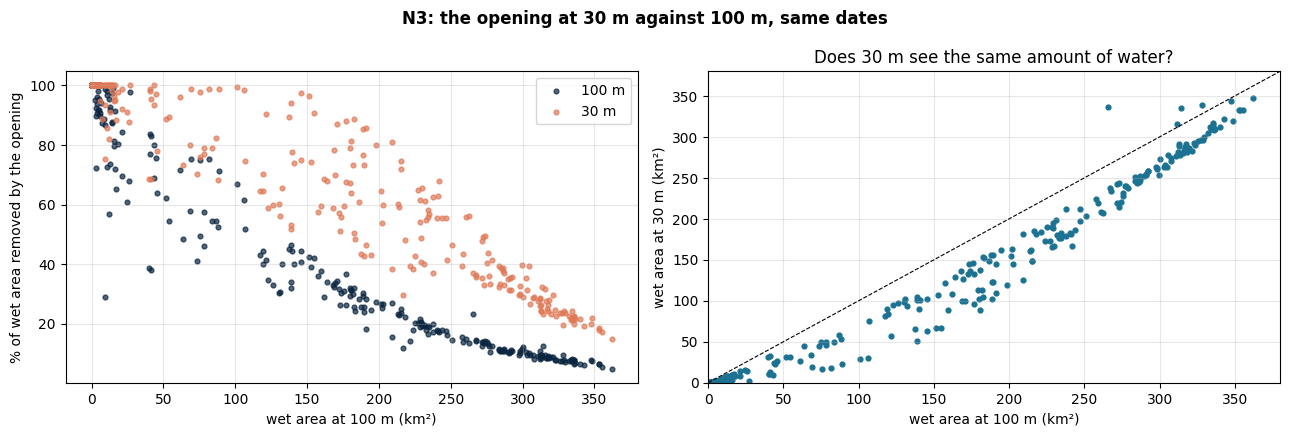


145 pair-dates merged at 100 m but separate at 30 m
         zone_kept  zone_dropped  zone_dry_obs  zone_dry_fill  zone_nodata
pair                                                                      
HLR-GMA      0.370         0.316         0.311          0.003          0.0
SHN-GMA      0.325         0.312         0.363          0.000          0.0

still one body at 30 m before the opening: 96% of these pair-dates
high -> the opening cut them (method effect); low -> dry or unobserved pixels did


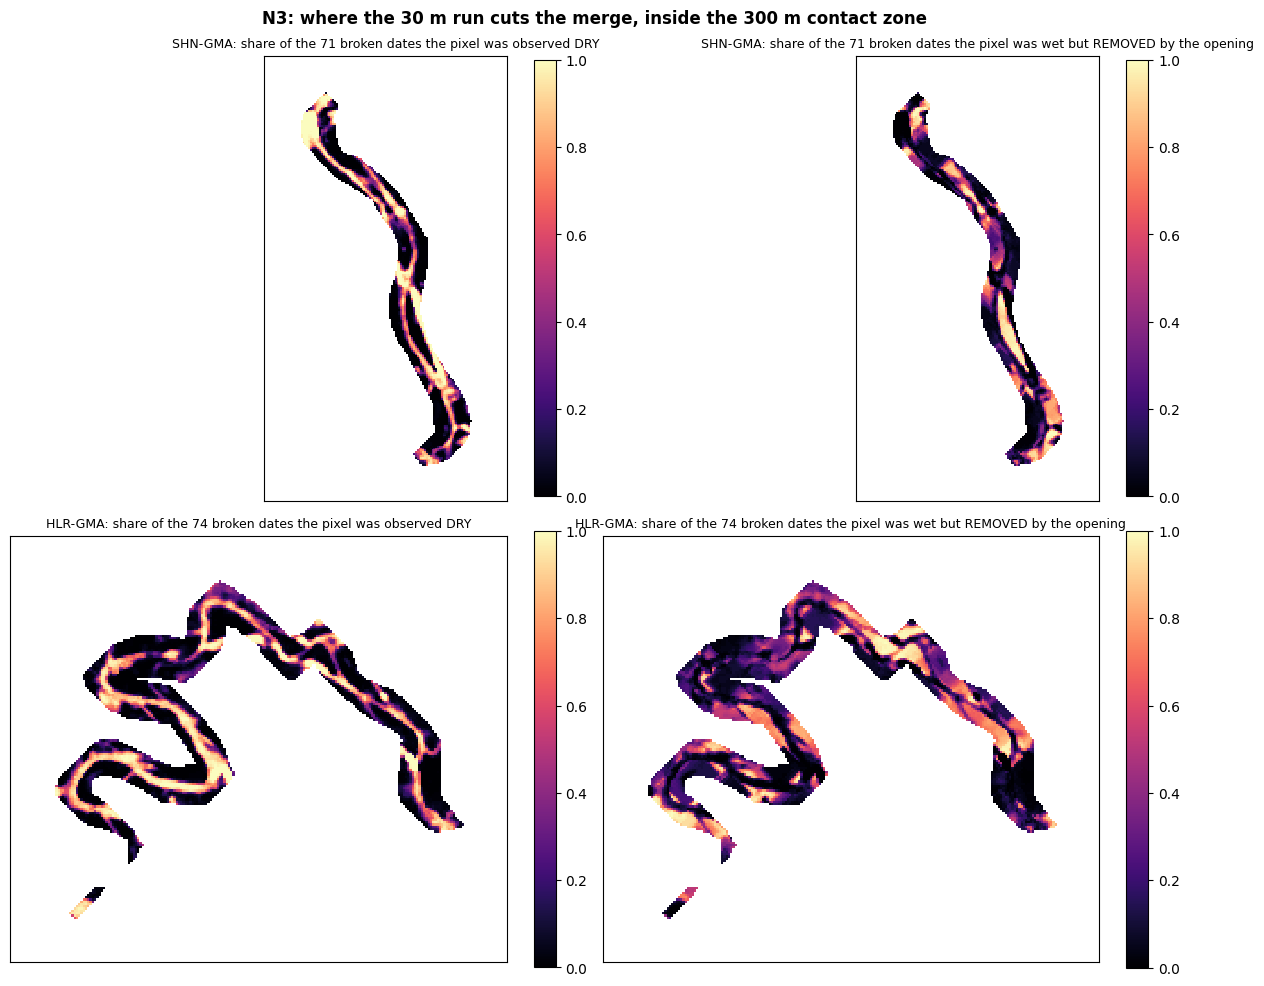

A thin line of persistent 'observed dry' = a real feature (embankment, village, road).
Scattered pixels that change from date to date = speckle or vegetation.


In [5]:
# ============ N3: WHY DOES 30 m BREAK THE MERGES? ============
# Part 1 (no shapefile needed). The bridge opening removes water necks narrower
# than about 300 m. At 100 m that is 1 iteration; at 30 m it is 5 iterations of
# the same cross. Five iterations also widen every small dry hole inside open
# water by 150 m in every direction, so a speckled but continuous water sheet
# can be cut. If that is what happens, the share of water REMOVED by the
# opening (code 4) is much higher at 30 m than at 100 m on the same dates.
def code_counts(path, year):
    rows = []
    with rasterio.open(path) as s:
        # pixel area: the grids are in degrees, so x and y sizes differ in metres
        px_km2 = (abs(s.res[0]) * 111320 * np.cos(np.radians(25.05))) * (abs(s.res[1]) * 110570) / 1e6
        for k, desc in enumerate(s.descriptions, 1):
            c = s.read(k)
            if (c == C_SKIP).all():
                continue
            n = {name: int((c == v).sum()) for name, v in
                 [("wet_kept", C_WET), ("wet_kept_fill", C_WETFILL), ("wet_dropped", C_DROP),
                  ("dry_obs", C_DRY), ("dry_fill", C_DRYFILL), ("nodata", C_NODATA)]}
            rows.append(dict(year=year, doy=dayidx(desc, year), px_km2=px_km2, **n))
    return pd.DataFrame(rows)

cc = []
for v in [REF, FINE]:
    for f in sorted(glob.glob(os.path.join(VIEWS[v], "codes_*.tif"))):
        y = int(re.search(r"(\d{4})", os.path.basename(f)).group(1))
        if v == REF and y not in MATS.get(FINE, {}):
            continue
        d = code_counts(f, y); d["view"] = v; cc.append(d)
if cc:
    CC = pd.concat(cc, ignore_index=True)
    wet = CC.wet_kept + CC.wet_kept_fill + CC.wet_dropped
    CC["drop_share"] = CC.wet_dropped / wet.where(wet > 0)
    CC["wet_km2"] = wet * CC.px_km2
    CC["kept_km2"] = (CC.wet_kept + CC.wet_kept_fill) * CC.px_km2
    CC.to_csv(os.path.join(OUT, "N3_code_counts.csv"), index=False)
    P = CC.pivot_table(index=["year", "doy"], columns="view", values=["drop_share", "wet_km2", "kept_km2"]).dropna()
    P.columns = [f"{a}_{b}" for a, b in P.columns]
    P = P.reset_index()
    print("Median over common dates (wet area includes water later removed by the opening):")
    print(P.drop(columns=["year", "doy"]).median().round(3).to_string())
    big = P[P[f"wet_km2_{REF}"] > P[f"wet_km2_{REF}"].quantile(.5)]
    print(f"\nWet half of the season ({len(big)} dates): water removed by the opening "
          f"{100*big[f'drop_share_{REF}'].median():.1f}% at 100 m, {100*big[f'drop_share_{FINE}'].median():.1f}% at 30 m")
    SCORE.append(("opening removes much more water at 30 m", "median share of wet area removed by the bridge opening, wet dates",
                  f"100 m {100*big[f'drop_share_{REF}'].median():.1f}%, 30 m {100*big[f'drop_share_{FINE}'].median():.1f}%"))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    for v, c in [(REF, "#0A2540"), (FINE, "#E07856")]:
        ax[0].scatter(P[f"wet_km2_{REF}"], P[f"drop_share_{v}"] * 100, s=12, c=c, alpha=.7, label=v)
    ax[0].set_xlabel("wet area at 100 m (km²)"); ax[0].set_ylabel("% of wet area removed by the opening")
    ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].scatter(P[f"wet_km2_{REF}"], P[f"wet_km2_{FINE}"], s=12, c="#1C7293")
    lim = [0, max(P[f"wet_km2_{REF}"].max(), P[f"wet_km2_{FINE}"].max()) * 1.05]
    ax[1].plot(lim, lim, "k--", lw=.8); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
    ax[1].set_xlabel("wet area at 100 m (km²)"); ax[1].set_ylabel("wet area at 30 m (km²)")
    ax[1].set_title("Does 30 m see the same amount of water?"); ax[1].grid(alpha=.3)
    fig.suptitle("N3: the opening at 30 m against 100 m, same dates", fontweight="bold")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, "N3_opening_share.png"), dpi=150); plt.show()

# Part 2 (needs the shapefile). On wet dates where 100 m says merged and 30 m
# says separate: what fills the contact zone at 30 m? And is the pair still
# connected at 30 m BEFORE the opening (all wet pixels, codes 2, 3, 4)?
#   connected before the opening -> the opening cut it (method effect)
#   not connected even before    -> dry or unobserved pixels cut it (a real
#                                   non-water feature, or radar noise)
N3B = None
if haors is not None and FINE in MATS and REF in MATS:
    rows, freq = [], {}
    for f in sorted(glob.glob(os.path.join(VIEWS[FINE], "codes_*.tif"))):
        y = int(re.search(r"(\d{4})", os.path.basename(f)).group(1))
        with rasterio.open(f) as s:
            meta = dict(shape=(s.height, s.width), transform=s.transform, crs=s.crs)
            from rasterio.features import geometry_mask
            hv = haors.to_crs(s.crs)
            masks = {h.haor_id: geometry_mask([h.geometry], meta["shape"], meta["transform"], invert=True)
                     for _, h in hv.iterrows()}
            k = max(1, int(round(CONTACT_M / (abs(s.res[0]) * 111320 * np.cos(np.radians(25.05))))))
            dil = {h: ndimage.binary_dilation(m, iterations=k) for h, m in masks.items()}
            zones = {p: dil[p.split("-")[0]] & dil[p.split("-")[1]] for p in ADJ}
            for p in ADJ:
                freq.setdefault(p, [np.zeros(meta["shape"], float), np.zeros(meta["shape"], float), 0, s.transform])
            for b, desc in enumerate(s.descriptions, 1):
                doy = dayidx(desc, y)
                code = None
                for p in ADJ:
                    if pair_state(REF, y, doy, p, tol=0) != "merged" or pair_state(FINE, y, doy, p, tol=0) != "separate":
                        continue
                    if code is None:
                        code = s.read(b)
                    z = zones[p]
                    zc = code[z]
                    wet_all = np.isin(code, [C_WET, C_WETFILL, C_DROP])
                    lab, _ = ndimage.label(wet_all)
                    a, bb = p.split("-")
                    va, vb = lab[masks[a] & (lab > 0)], lab[masks[bb] & (lab > 0)]
                    pre = bool(va.size and vb.size and np.bincount(va).argmax() == np.bincount(vb).argmax())
                    rows.append(dict(year=y, doy=doy, pair=p, connected_before_opening=pre,
                                     zone_kept=np.isin(zc, [C_WET, C_WETFILL]).mean(),
                                     zone_dropped=(zc == C_DROP).mean(), zone_dry_obs=(zc == C_DRY).mean(),
                                     zone_dry_fill=(zc == C_DRYFILL).mean(), zone_nodata=(zc == C_NODATA).mean()))
                    freq[p][0] += (code == C_DRY) & z
                    freq[p][1] += (code == C_DROP) & z
                    freq[p][2] += 1
    N3B = pd.DataFrame(rows)
    if len(N3B):
        N3B.to_csv(os.path.join(OUT, "N3_contact_zone_30m.csv"), index=False)
        print(f"\n{len(N3B)} pair-dates merged at 100 m but separate at 30 m")
        print(N3B.groupby("pair")[["zone_kept", "zone_dropped", "zone_dry_obs", "zone_dry_fill", "zone_nodata"]].mean().round(3).to_string())
        sh = N3B.connected_before_opening.mean()
        print(f"\nstill one body at 30 m before the opening: {100*sh:.0f}% of these pair-dates")
        print("high -> the opening cut them (method effect); low -> dry or unobserved pixels did")
        SCORE.append(("30 m breaks made by the opening", "share of 100 m merged / 30 m separate pair-dates that are one body before the opening",
                      f"{100*sh:.0f}% (n {len(N3B)})"))
        fig, ax = plt.subplots(len(ADJ), 2, figsize=(12, 5 * len(ADJ)), squeeze=False)
        for i, p in enumerate(ADJ):
            dry, drop, n, tr = freq[p]
            if n == 0:
                ax[i][0].axis("off"); ax[i][1].axis("off"); continue
            z = zones[p]; rr, cc_ = np.where(z)
            win = (slice(max(rr.min() - 20, 0), rr.max() + 20), slice(max(cc_.min() - 20, 0), cc_.max() + 20))
            for jj, (arr, ttl) in enumerate([(dry, "observed DRY"), (drop, "wet but REMOVED by the opening")]):
                im = ax[i][jj].imshow(np.where(z, arr / n, np.nan)[win], cmap="magma", vmin=0, vmax=1, interpolation="nearest")
                ax[i][jj].set_title(f"{p}: share of the {n} broken dates the pixel was {ttl}", fontsize=9)
                ax[i][jj].set_xticks([]); ax[i][jj].set_yticks([])
                plt.colorbar(im, ax=ax[i][jj], fraction=.04)
        fig.suptitle("N3: where the 30 m run cuts the merge, inside the 300 m contact zone", fontweight="bold")
        plt.tight_layout(); plt.savefig(os.path.join(FIGS, "N3_where_30m_cuts.png"), dpi=150); plt.show()
        print("A thin line of persistent 'observed dry' = a real feature (embankment, village, road).")
        print("Scattered pixels that change from date to date = speckle or vegetation.")
else:
    print("\nN3 part 2 needs the shapefile; skipped")

In [6]:
# ============ N4: THE 30 m RESULT WITH OTHER BRIDGE SETTINGS (from the code rasters) ============
# The code rasters store, for every date and pixel, whether the FILLED band was
# wet (codes 2, 3, 4), dry (1, 5) or unobserved (6). That is exactly the input
# of the connectivity step, so the step can be re-run here with other settings
# without the 30 m stacks. Variants:
#   BRIDGE 5 (as run)  links < ~330 m removed      BRIDGE 0  nothing removed
#   BRIDGE 1           links < ~90 m removed       BRIDGE 2  links < ~150 m removed
#   MAJ3 + BRIDGE 5    3x3 majority vote on the water map first (speckle filter)
#   90 m + BRIDGE 1    water map averaged to 90 m blocks (>= 50% wet), then the
#                      100 m rule: shows whether coarse pixels alone restore merges
# Output: share of the 100 m merged pair-dates that each variant also calls merged.
if haors is None or core is None or FINE not in MATS:
    print("N4 needs the shapefile and haor_validation_core.py; skipped")
else:
    from rasterio.features import geometry_mask
    def majority3(w):
        return ndimage.uniform_filter(w.astype(float), 3) > 0.5
    def block3(w):
        h, wd = (w.shape[0] // 3) * 3, (w.shape[1] // 3) * 3
        return w[:h, :wd].reshape(h // 3, 3, wd // 3, 3).mean(axis=(1, 3)) >= 0.5
    VARIANTS = {"BRIDGE 5 (as run)": (None, 5), "BRIDGE 0": (None, 0), "BRIDGE 1": (None, 1),
                "BRIDGE 2": (None, 2), "MAJ3 + BRIDGE 5": (majority3, 5), "90 m + BRIDGE 1": (block3, 1)}
    rows = []
    for f in sorted(glob.glob(os.path.join(VIEWS[FINE], "codes_*.tif"))):
        y = int(re.search(r"(\d{4})", os.path.basename(f)).group(1))
        with rasterio.open(f) as s:
            hv = haors.to_crs(s.crs)
            m30 = {h.haor_id: geometry_mask([h.geometry], (s.height, s.width), s.transform, invert=True)
                   for _, h in hv.iterrows()}
            m90 = {h: block3(m) for h, m in m30.items()}
            min_px30 = int(round(10 * (100 / 30) ** 2))
            for b, desc in enumerate(s.descriptions, 1):
                doy = dayidx(desc, y)
                st100 = {p: pair_state(REF, y, doy, p, tol=0) for p in ADJ}
                if not any(v in ("merged", "separate") for v in st100.values()):
                    continue
                code = s.read(b)
                if (code == C_SKIP).all():
                    continue
                wet = np.isin(code, [C_WET, C_WETFILL, C_DROP])
                for name, (pre, br) in VARIANTS.items():
                    w = pre(wet) if pre else wet
                    masks = m90 if pre is block3 else m30
                    mp = int(round(10 * (100 / 90) ** 2)) if pre is block3 else min_px30
                    w2 = ndimage.binary_opening(w, iterations=br) if br else w
                    lab, n = ndimage.label(w2)
                    if n:
                        sz = ndimage.sum(np.ones_like(lab), lab, index=np.arange(1, n + 1))
                        w2 = w2 & np.isin(lab, np.where(sz >= mp)[0] + 1)
                        lab, n = ndimage.label(w2)
                    comp = {}
                    for h, m in masks.items():
                        v = lab[m & (lab > 0)]
                        comp[h] = int(np.bincount(v).argmax()) if v.size else 0
                    for p in ADJ:
                        if st100[p] not in ("merged", "separate"):
                            continue
                        a, bb = p.split("-")
                        rows.append(dict(year=y, doy=doy, pair=p, variant=name, state100=st100[p],
                                         merged=comp[a] > 0 and comp[a] == comp[bb]))
    N4 = pd.DataFrame(rows)
    N4.to_csv(os.path.join(OUT, "N4_30m_variants.csv"), index=False)
    t = N4.groupby(["variant", "state100"]).merged.mean().unstack().round(3)
    t.columns = [f"share merged | 100 m {c}" for c in t.columns]
    print(t.loc[list(VARIANTS)].to_string())
    print("""
Left column: of the pair-dates merged at 100 m, the share each variant also merges.
Right column: of the pair-dates separate at 100 m, the share each variant merges
(a variant that merges everything is not better, only looser).
If BRIDGE 0 or MAJ3 brings the left column close to 1 while the right stays low,
the 30 m failure was the opening acting on speckle, not missing water.""")
    best = t.iloc[:, -1] if t.shape[1] else None
    SCORE.append(("30 m merges restored by gentler settings", "share of 100 m merged pair-dates merged at 30 m, BRIDGE 0 and MAJ3",
                  " | ".join(f"{k}: {t.loc[k].iloc[0]:.2f}" for k in ["BRIDGE 5 (as run)", "BRIDGE 0", "MAJ3 + BRIDGE 5", "90 m + BRIDGE 1"] if k in t.index)))

                   share merged | 100 m merged  share merged | 100 m separate
variant                                                                      
BRIDGE 5 (as run)                        0.065                          0.000
BRIDGE 0                                 0.961                          0.081
BRIDGE 1                                 0.935                          0.049
BRIDGE 2                                 0.768                          0.016
MAJ3 + BRIDGE 5                          0.342                          0.004
90 m + BRIDGE 1                          0.723                          0.012

Left column: of the pair-dates merged at 100 m, the share each variant also merges.
Right column: of the pair-dates separate at 100 m, the share each variant merges
(a variant that merges everything is not better, only looser).
If BRIDGE 0 or MAJ3 brings the left column close to 1 while the right stays low,
the 30 m failure was the opening acting on speckle, not missing wa

159 passes, 714 haor-pass levels


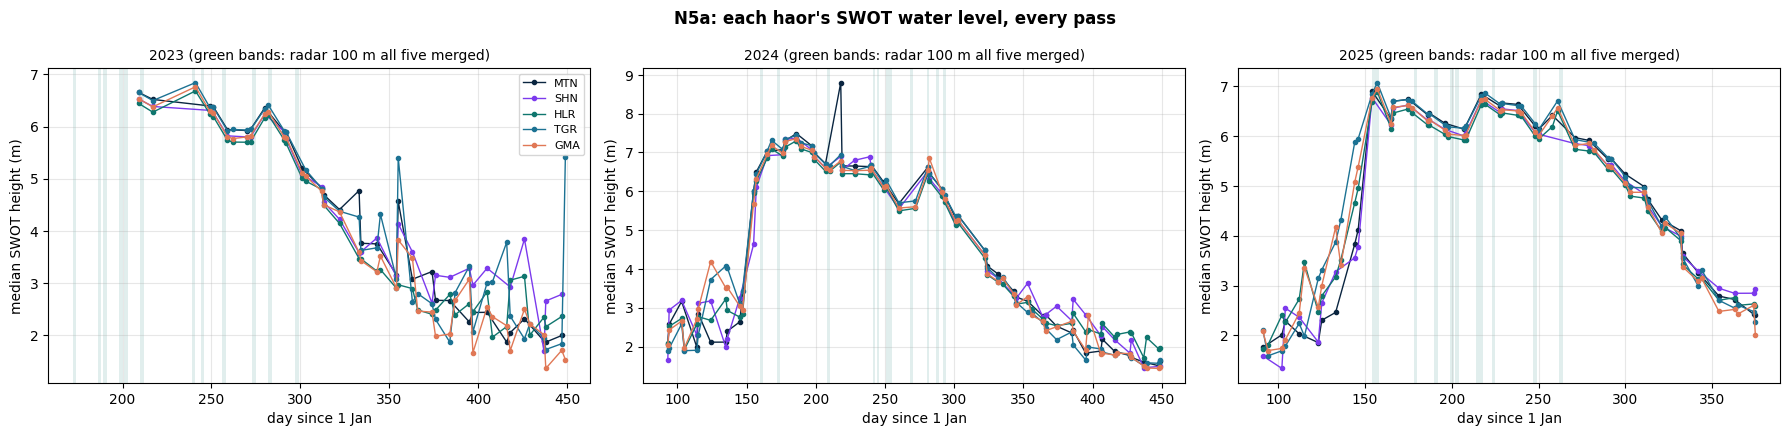


N5b: drawdown (days 280 to 380), each haor's level minus the pass median (m),
passes that see all five haors only. Positive = holds water higher than the others.
haor     GMA    HLR    MTN    SHN    TGR
hyear                                   
2023  -0.078 -0.146  0.112  0.001  0.013
2024   0.000 -0.078  0.082 -0.001  0.010
2025  -0.042 -0.083  0.112  0.005  0.000
Radar drain order (Kendall's W 0.909): GMA first, MTN last in all seven years.
If MTN sits highest and GMA lowest here, two sensors agree on the order.

N5c: wet passes, median |level difference| (m) by centroid distance and radar state
         median            size         
state    merged separate merged separate
dist_bin                                
(0, 10]   0.091    0.099     56       70
(10, 15]  0.081    0.119     53       75
(15, 20]  0.169    0.156     31       31

|diff| = 0.043 + 0.0051 x distance_km + 0.010 x separate
  slope per km   +0.0051  [+0.0044, +0.0058]  (date-block bootstrap)
  separate extra +0.01

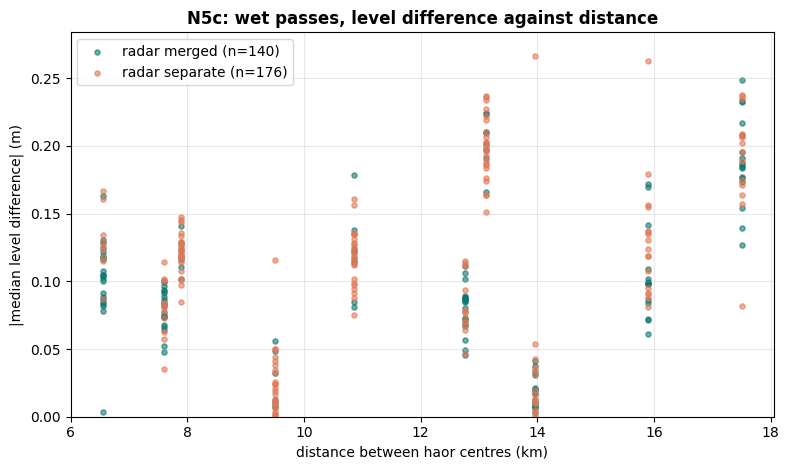

In [7]:
# ============ N5: PER-HAOR SWOT LEVELS, DRAWDOWN ORDER, AND THE DISTANCE CONTROL ============
# (a) median SWOT height of each haor on every pass (strict pixel filter, as in
#     the SWOT notebook), as a hydrograph per year
# (b) during drawdown, which haor holds the highest water? Compare with the
#     radar drain order (MTN last in all seven years)
# (c) S5 found that different radar bodies sit 0.25 m apart and one body only
#     0.08 m. Haors in different bodies are often also FAR apart, and SWOT
#     heights change with distance (regional slope, cross-track error). Here
#     every pair of haors on every wet pass gets its level difference, its
#     centroid distance and its 100 m state, so the two can be separated.
WATER_FRAC_MIN, QUAL_MAX, UNCERT_MAX, MIN_PX_HAOR = 0.5, 1, 1.0, 30
if haors is None or not os.path.isdir(PIX_DIR):
    print("N5 needs the shapefile and validation/swot_pixels_all/; skipped")
else:
    from shapely import contains_xy
    IX = pd.read_csv(os.path.join(PIX_DIR, "index.csv"))
    IX = IX[IX.res == "100m"]
    hU = haors.to_crs(UTM).set_index("haor_id")
    geoms = haors.set_index("haor_id").geometry
    cent = {h: np.array(hU.geometry[h].centroid.coords[0]) for h in HAOR_IDS}
    rows = []
    for date, g in IX.groupby("date"):
        frames = []
        for f in g.file:
            z = np.load(os.path.join(PIX_DIR, f))
            frames.append(pd.DataFrame({k: z[k] for k in z.files}))
        df = pd.concat(frames, ignore_index=True)
        df = df[(df.water_frac >= WATER_FRAC_MIN) & (df.wse_qual <= QUAL_MAX) &
                (df.wse_uncert <= UNCERT_MAX) & np.isfinite(df.wse)]
        for h in HAOR_IDS:
            inside = contains_xy(geoms[h], df.lon.values, df.lat.values)
            if inside.sum() >= MIN_PX_HAOR:
                w = df.wse.values[inside]
                rows.append(dict(date=date, haor=h, wse=float(np.median(w)), n=int(inside.sum()),
                                 iqr=float(np.subtract(*np.percentile(w, [75, 25])))))
    HL = pd.DataFrame(rows)
    HL["date"] = pd.to_datetime(HL.date)
    HL["hyear"] = np.where(HL.date.dt.month >= 4, HL.date.dt.year, HL.date.dt.year - 1)
    HL["doy"] = (HL.date - pd.to_datetime(HL.hyear.astype(str) + "-01-01")).dt.days.astype(float)
    HL.to_csv(os.path.join(OUT, "N5_haor_levels.csv"), index=False)
    print(f"{HL.date.nunique()} passes, {len(HL)} haor-pass levels")

    hy = sorted(HL.hyear.unique())
    fig, ax = plt.subplots(1, len(hy), figsize=(6 * len(hy), 4.4), squeeze=False)
    for j, y in enumerate(hy):
        g = HL[HL.hyear == y]
        for h in HAOR_IDS:
            gh = g[g.haor == h].sort_values("doy")
            ax[0][j].plot(gh.doy, gh.wse, "o-", ms=3, lw=1, color=HAOR_COLORS[h], label=h)
        m = MATS[REF].get(int(y))
        if m is not None:
            nz = m[HAOR_IDS].gt(0).all(axis=1) & m[HAOR_IDS].nunique(axis=1).eq(1)
            for d in m.index[nz]:
                ax[0][j].axvspan(d - 1, d + 1, color="#0F766E", alpha=.12, lw=0)
        ax[0][j].set_title(f"{y} (green bands: radar 100 m all five merged)", fontsize=10)
        ax[0][j].set_xlabel("day since 1 Jan"); ax[0][j].set_ylabel("median SWOT height (m)"); ax[0][j].grid(alpha=.3)
    ax[0][0].legend(fontsize=8)
    fig.suptitle("N5a: each haor's SWOT water level, every pass", fontweight="bold")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, "N5a_haor_levels.png"), dpi=150); plt.show()

    # (b) drawdown: level of each haor relative to the pass median, days 280 to 380
    D = HL[(HL.doy >= 280) & (HL.doy <= 380)].copy()
    full = D.groupby("date").haor.transform("nunique") == 5
    D = D[full]
    if len(D):
        D["rel"] = D.wse - D.groupby("date").wse.transform("median")
        rel = D.pivot_table(index="hyear", columns="haor", values="rel", aggfunc="median").round(3)
        print("\nN5b: drawdown (days 280 to 380), each haor's level minus the pass median (m),")
        print("passes that see all five haors only. Positive = holds water higher than the others.")
        print(rel.to_string())
        print("Radar drain order (Kendall's W 0.909): GMA first, MTN last in all seven years.")
        print("If MTN sits highest and GMA lowest here, two sensors agree on the order.")
        rel.to_csv(os.path.join(OUT, "N5b_drawdown_relative_levels.csv"))
    else:
        print("\nN5b: no drawdown pass sees all five haors")

    # (c) the distance control
    rows = []
    for (date, g) in HL.groupby("date"):
        y = int(g.hyear.iloc[0]); doy = float(g.doy.iloc[0])
        m = MATS[REF].get(y)
        if m is None:
            continue
        k = np.abs(m.index.values - doy)
        if k.min() > 3:
            continue
        lv = g.set_index("haor").wse
        for i, a in enumerate(HAOR_IDS):
            for b in HAOR_IDS[i + 1:]:
                if a in lv and b in lv:
                    st = pair_state(REF, y, float(m.index.values[int(k.argmin())]), f"{a}-{b}", tol=0)
                    rows.append(dict(date=date, year=y, doy=doy, pair=f"{a}-{b}", state=st,
                                     diff=abs(lv[a] - lv[b]), dist_km=np.linalg.norm(cent[a] - cent[b]) / 1000))
    DC = pd.DataFrame(rows)
    cfr = ST.groupby("date").cluster_frac.first()
    DC["cluster_frac"] = pd.to_datetime(DC.date).dt.strftime("%Y-%m-%d").map(cfr)
    DC.to_csv(os.path.join(OUT, "N5c_pair_levels.csv"), index=False)
    Wd = DC[(DC.cluster_frac >= WET) & DC.state.isin(["merged", "separate"])].copy()
    if len(Wd):
        Wd["dist_bin"] = pd.cut(Wd.dist_km, [0, 10, 15, 20, 25, 40])
        print("\nN5c: wet passes, median |level difference| (m) by centroid distance and radar state")
        print(Wd.pivot_table(index="dist_bin", columns="state", values="diff", aggfunc=["median", "size"]).round(3).to_string())
        # regression: diff ~ distance + separate
        X = np.column_stack([np.ones(len(Wd)), Wd.dist_km.values, (Wd.state == "separate").values.astype(float)])
        beta, *_ = np.linalg.lstsq(X, Wd["diff"].values, rcond=None)
        rng = np.random.default_rng(3); bs = []
        dates = Wd.date.unique()
        for _ in range(1000):
            pick = rng.choice(dates, len(dates))
            S = pd.concat([Wd[Wd.date == d] for d in pick])
            Xs = np.column_stack([np.ones(len(S)), S.dist_km.values, (S.state == "separate").values.astype(float)])
            bs.append(np.linalg.lstsq(Xs, S["diff"].values, rcond=None)[0])
        lo, hi = np.percentile(np.array(bs), [2.5, 97.5], axis=0)
        print(f"\n|diff| = {beta[0]:.3f} + {beta[1]:.4f} x distance_km + {beta[2]:.3f} x separate")
        print(f"  slope per km   {beta[1]:+.4f}  [{lo[1]:+.4f}, {hi[1]:+.4f}]  (date-block bootstrap)")
        print(f"  separate extra {beta[2]:+.3f}  [{lo[2]:+.3f}, {hi[2]:+.3f}] m")
        print("If the 'separate extra' interval includes 0, the S5 contrast was distance, not bodies.")
        SCORE.append(("S5 survives the distance control", "wet passes: extra |level difference| for separate pairs at equal distance, 95% CI excludes 0",
                      f"{'YES' if lo[2] > 0 else 'NO'} ({beta[2]:+.3f} m [{lo[2]:+.3f}, {hi[2]:+.3f}])"))
        fig, ax = plt.subplots(figsize=(8, 4.8))
        for st, c in [("merged", "#0F766E"), ("separate", "#E07856")]:
            q = Wd[Wd.state == st]
            ax.scatter(q.dist_km, q["diff"], s=14, alpha=.6, c=c, label=f"radar {st} (n={len(q)})")
        ax.set_xlabel("distance between haor centres (km)"); ax.set_ylabel("|median level difference| (m)")
        ax.set_ylim(0, min(1.0, Wd["diff"].quantile(.98) * 1.2)); ax.legend(); ax.grid(alpha=.3)
        ax.set_title("N5c: wet passes, level difference against distance", fontweight="bold")
        plt.tight_layout(); plt.savefig(os.path.join(FIGS, "N5c_distance_control.png"), dpi=150); plt.show()

In [8]:
# ============ N6: THE BLIND CARDS. WHAT DO THE EYE LABELS FOLLOW? ============
# Round 1: kappa -0.15 (agreement 49%), worse than chance. Cause found: the
# Sentinel-1 export masks pixels below -30 dB and writes them as -32768, and the
# card drew those as NaN, i.e. WHITE. The calmest open water, the clearest sign
# of connection, looked like the brightest land. Peak and last-merge cards had
# 18 to 44% of the haor box drawn white and were labelled "separate". The round-1
# labels cannot score the algorithm. Part 1 shows this from the files; part 2
# writes round-2 cards with the display fixed.
KEYF = os.path.join(VAL, "reference_key_ids.csv")
LABF = os.path.join(VAL, "reference_labels.csv")
KDF = os.path.join(VAL, "key_dates.csv")
V5F = os.path.join(VAL, "V5_100m_vs_20m.csv")
if all(os.path.exists(f) for f in [KEYF, LABF, KDF]):
    L = pd.read_csv(LABF).merge(pd.read_csv(KEYF), on="card")
    L = L.merge(pd.read_csv(KDF)[["label", "cluster_frac", "role"]], on="label", how="left")
    L["alg100"] = [pair_state(REF, r.year, r.doy, r.pair, tol=0) for r in L.itertuples()]
    if os.path.exists(V5F):
        v5 = pd.read_csv(V5F)[["label", "pair", "merged_20m"]]
        L = L.merge(v5, on=["label", "pair"], how="left")
    L["eye"] = L.your_label.astype(str).str.upper()
    # share of the haor box drawn white on each card (masked pixels below -30 dB)
    IMG6 = os.path.join(VAL, "images")
    if os.path.isdir(IMG6):
        from rasterio.windows import from_bounds as _fb
        wsh = {}
        for lab_, date_ in L[["label", "date"]].drop_duplicates().itertuples(index=False):
            h = glob.glob(os.path.join(IMG6, f"{lab_}_S1_{date_.replace('-', '')}*.tif"))
            if h:
                with rasterio.open(h[0]) as s:
                    v = s.read(1, window=_fb(91.0, 24.97, 91.25, 25.15, s.transform))
                wsh[lab_] = float((v == -32768).mean())
        L["white_share"] = L.label.map(wsh)
    L.to_csv(os.path.join(OUT, "N6_cards_audit.csv"), index=False)
    E = L[L.eye.isin(["C", "S"])]
    def kappa(e, a):
        po = (e == a).mean(); pe = sum((e == k).mean() * (a == k).mean() for k in "CS")
        return po, (po - pe) / (1 - pe)
    a100 = np.where(E.alg100 == "merged", "C", "S")
    print(f"eye vs 100 m algorithm : agreement {kappa(E.eye.values, a100)[0]:.2f}, kappa {kappa(E.eye.values, a100)[1]:+.2f}, n {len(E)}")
    if "merged_20m" in E:
        e2 = E.dropna(subset=["merged_20m"])
        a20 = np.where(e2.merged_20m.astype(bool), "C", "S")
        print(f"eye vs 20 m flood flag : agreement {kappa(e2.eye.values, a20)[0]:.2f}, kappa {kappa(e2.eye.values, a20)[1]:+.2f}, n {len(e2)}")
    E = E.assign(eyeC=(E.eye == "C").astype(int), algC=(a100 == "C").astype(int))
    E["frac_bin"] = pd.cut(E.cluster_frac, [0, .3, .6, .8, .88, 1.0])
    print("\nShare labelled CONNECTED, by how flooded the cluster was:")
    print(E.groupby("frac_bin")[["eyeC", "algC"]].agg(["mean", "size"]).round(2).to_string())
    print("\nBy key-date role:")
    print(E.groupby("role")[["eyeC", "algC"]].mean().round(2).to_string())
    print("""
Reading: the algorithm says CONNECTED more often the more the cluster is flooded,
as water physically requires. Your C share falls at the highest flood because
those cards showed the open water white (see white_share).""")
    if "white_share" in E:
        for lo, hi in [(0, .05), (.05, .15), (.15, 1.01)]:
            q = E[(E.white_share >= lo) & (E.white_share < hi)]
            if len(q):
                print(f"cards with {lo:.0%} to {min(hi,1):.0%} of the box drawn white: n {len(q)}, labelled C {q.eyeC.mean():.0%}, algorithm C {q.algC.mean():.0%}")
    SCORE.append(("round-1 blind cards usable", "cards drew the water as water",
                  "NO: masked open water drawn white; redo with round 2"))
else:
    print("card files not found; skipped")

# Part 2: ROUND 2 CARDS (needs the 20 m images in validation/images and the shapefile)
# What changes, and why:
#   * one card per PAIR and date, zoomed on the shared boundary (+-4 km) at full
#     20 m detail, instead of the whole cluster at screen resolution
#   * the same window on the driest exported date of that year beside it, so a
#     bright line that is ALWAYS there (village, road, embankment) can be told
#     apart from a bright line that is there only on this date
#   * a written definition on every card
#   * 8 cards repeated under new numbers: the share you label the same way twice
#     is your own consistency, the ceiling for any agreement with the algorithm
# The cards are written ONCE, the first time this cell runs. After that the
# existing cards, key and your labels are never overwritten.
CARDS2 = os.path.join(OUT, "round2_cards")
K2F    = os.path.join(OUT, "round2_card_key.csv")        # the answers: do not open while labelling
L2F    = os.path.join(OUT, "round2_labels.csv")          # you fill the your_label column
IMAGES = os.path.join(VAL, "images")
MAKE_ROUND2 = not os.path.exists(K2F)
if MAKE_ROUND2 and haors is not None and os.path.isdir(IMAGES):
    from rasterio.windows import from_bounds
    import gc
    os.makedirs(CARDS2, exist_ok=True)
    K = pd.read_csv(KDF)
    def s1_path(label, date):
        h = glob.glob(os.path.join(IMAGES, f"{label}_S1_{date.replace('-', '')}*.tif"))
        return h[0] if h else None
    K = K[[s1_path(r.label, r.date) is not None for r in K.itertuples()]]
    hU2 = haors.set_index("haor_id")
    items = [(r, p) for r in K.itertuples() for p in ADJ]
    rng = np.random.default_rng(20261014)
    rep = rng.choice(len(items), 8, replace=False)
    items = items + [items[i] for i in rep]
    order = rng.permutation(len(items))
    key, sheet = [], []
    DEF = ("C = a continuous dark (water) path crosses the red boundary somewhere\n"
           "S = a bright (land) line runs along the WHOLE boundary inside the window\n"
           "U = cannot tell (noise, no data, image edge)")
    for n, idx in enumerate(order):
        r, p = items[idx]
        a, b = p.split("-")
        line = hU2.geometry[a].boundary.intersection(hU2.geometry[b].buffer(0.0005))
        x0, y0, x1, y1 = line.bounds
        pad = 0.04
        dry = K[(K.year == r.year)].sort_values("cluster_frac").iloc[0]
        fig, ax = plt.subplots(1, 2, figsize=(13, 6.6))
        win_b = (x0 - pad, y0 - pad, x1 + pad, y1 + pad)
        for jj, rr in enumerate([r, dry]):
            with rasterio.open(s1_path(rr.label, rr.date)) as s:
                # read only the window around this boundary: full scenes for ~100 cards exhaust memory
                w = from_bounds(*win_b, s.transform).round_offsets().round_lengths()
                raw = s.read(1, window=w, boundless=True, fill_value=-32768).astype(np.float32)
                wb = rasterio.windows.bounds(w, s.transform)
            # -32768 marks pixels below -30 dB (the calmest open water), NOT missing data:
            # draw them black. Round 1 drew them white, which made open water look like land.
            vv = np.where(raw == -32768, -30.0, raw / 100)
            ax[jj].imshow(vv, extent=(wb[0], wb[2], wb[1], wb[3]), cmap="gray", vmin=-25, vmax=-2)
            haors.boundary.plot(ax=ax[jj], color="#38BDF8", lw=.6)
            gpd.GeoSeries([line], crs=haors.crs).plot(ax=ax[jj], color="red", lw=1.5)
            ax[jj].set_xlim(x0 - pad, x1 + pad); ax[jj].set_ylim(y0 - pad, y1 + pad)
            ax[jj].set_title("LABEL THIS ONE" if jj == 0 else "reference: the driest date of the same year")
            del raw, vv
        cid = f"v2card{n:03d}"
        fig.suptitle(f"{cid}   pair {a} | {b}\n{DEF}", fontsize=10, ha="left", x=0.02)
        plt.tight_layout(rect=[0, 0, 1, 0.86]); plt.savefig(os.path.join(CARDS2, f"{cid}.png"), dpi=130); plt.close(fig); gc.collect()
        key.append(dict(card=cid, label=r.label, year=r.year, doy=r.doy, date=r.date, pair=p, repeat_of=None))
        sheet.append(dict(card=cid, pair=p, your_label=""))
    KEY2 = pd.DataFrame(key)
    first = {}
    for i, k in enumerate(KEY2.itertuples()):
        tag = (k.label, k.pair)
        if tag in first:
            KEY2.loc[i, "repeat_of"] = first[tag]
        else:
            first[tag] = k.card
    KEY2.to_csv(K2F, index=False)
    if not os.path.exists(L2F):
        pd.DataFrame(sheet).sort_values("card").to_csv(L2F, index=False)
    print(f"wrote {len(sheet)} round-2 cards to {CARDS2}")
    print("label them: fill your_label (C, S or U) in next_checks/round2_labels.csv; do not open round2_card_key.csv")
elif MAKE_ROUND2:
    print("round-2 cards need validation/images and the shapefile; skipped")
else:
    print(f"round-2 cards already exist in {CARDS2} (not rewritten)")

# Scoring round 2 (runs once round2_labels.csv is filled)
if os.path.exists(L2F) and os.path.exists(K2F):
    L2 = pd.read_csv(L2F).merge(pd.read_csv(K2F), on=["card", "pair"])
    L2["eye"] = L2.your_label.astype(str).str.upper()
    if L2.eye.isin(["C", "S"]).sum() >= 10:
        rp = L2.dropna(subset=["repeat_of"])
        same = [(r.eye == L2.set_index("card").loc[r.repeat_of, "eye"]) for r in rp.itertuples()]
        print(f"round 2: you labelled {np.mean(same):.0%} of the {len(same)} repeated cards the same way twice")
        E2 = L2[L2.eye.isin(["C", "S"]) & L2.repeat_of.isna()].copy()
        for view in VIEWS:
            st = [pair_state(view, r.year, r.doy, r.pair, tol=0) for r in E2.itertuples()]
            ok = np.array([x in ("merged", "separate") for x in st])
            if ok.sum() < 10:
                continue
            e = E2.eye.values[ok]; a = np.where(np.array(st)[ok] == "merged", "C", "S")
            po = (e == a).mean(); pe = sum((e == k).mean() * (a == k).mean() for k in "CS")
            k2 = (po - pe) / (1 - pe) if pe < 1 else np.nan
            E2[f"alg_{view}"] = st
            print(f"  eye vs {view:24s}: agreement {po:.2f}, kappa {k2:+.2f} (n {ok.sum()})")
            SCORE.append((f"round-2 cards: eye agrees with {view}", "kappa >= 0.6 (self-consistency >= 0.85)",
                          f"kappa {k2:+.2f}, self-consistency {np.mean(same):.2f}"))
        E2.to_csv(os.path.join(OUT, "N6_round2_scored.csv"), index=False)
    else:
        print("round2_labels.csv is not filled yet: no round-2 score")

eye vs 100 m algorithm : agreement 0.49, kappa -0.15, n 87
eye vs 20 m flood flag : agreement 0.29, kappa -0.34, n 85

Share labelled CONNECTED, by how flooded the cluster was:
             eyeC       algC     
             mean size  mean size
frac_bin                         
(0.0, 0.3]   0.50   12  0.00   12
(0.3, 0.6]   1.00   16  0.06   16
(0.6, 0.8]   0.74   19  0.74   19
(0.8, 0.88]  0.82   22  1.00   22
(0.88, 1.0]  0.50   18  1.00   18

By key-date role:
                eyeC  algC
role                      
event1          0.00  0.00
event2          0.00  0.00
event3          0.50  0.00
event4          0.50  0.00
event5          1.00  1.00
firstmerge_on   0.93  1.00
firstmerge_pre  1.00  0.36
lastmerge_on    0.38  1.00
lastmerge_post  0.93  0.21
peak            0.20  1.00
swotpair_on     1.00  1.00
swotpair_pre    1.00  0.33

Reading: the algorithm says CONNECTED more often the more the cluster is flooded,
as water physically requires. Your C share falls at the highest flood b

In [9]:
# ============ N7: ADJACENCY TOLERANCE AND THE 'ONLY ADJACENT HAORS CONNECT' RULE ============
# Round 1 called only SHN-GMA and HLR-GMA adjacent (they are 34 to 37 m apart and
# the tolerance was 50 m); the five other neighbouring pairs are 50 to 76 m
# apart. With only two adjacent pairs, the ADJACENT_ONLY rule cannot join five haors, so its 0 merged dates is a
# property of the digitising, not of the water. This prints adjacency at
# several tolerances. The gaps of 34 to 76 m between polygons are smaller than
# one 100 m pixel: check on the optical image whether they are real (a river,
# an embankment) or digitising slivers.
if haors is None or core is None:
    print("N7 needs the shapefile and haor_validation_core.py; skipped")
else:
    rows = []
    for tol in [50, 75, 100, 150, 250]:
        a = core.adjacency(haors, tol_m=tol)
        rows.append(dict(tol_m=tol, n_adjacent=int(a.adjacent.sum()),
                         pairs=", ".join(a.loc[a.adjacent, "pair"])))
    print(pd.DataFrame(rows).to_string(index=False))
    print("\nIf MTN and TGR join at 75 to 100 m, re-run haor_parameter_sensitivity.py with")
    print("core.adjacency(haors, tol_m=100) for the ADJACENT_ONLY variant before quoting it.")

 tol_m  n_adjacent                                                         pairs
    50           2                                              SHN-GMA, HLR-GMA
    75           6          MTN-SHN, MTN-TGR, MTN-GMA, SHN-GMA, HLR-GMA, TGR-GMA
   100           7 MTN-SHN, MTN-TGR, MTN-GMA, SHN-HLR, SHN-GMA, HLR-GMA, TGR-GMA
   150           7 MTN-SHN, MTN-TGR, MTN-GMA, SHN-HLR, SHN-GMA, HLR-GMA, TGR-GMA
   250           7 MTN-SHN, MTN-TGR, MTN-GMA, SHN-HLR, SHN-GMA, HLR-GMA, TGR-GMA

If MTN and TGR join at 75 to 100 m, re-run haor_parameter_sensitivity.py with
core.adjacency(haors, tol_m=100) for the ADJACENT_ONLY variant before quoting it.


per family: median incidence angle and median VV over permanent water (dB)
               inc_mean  vv_perm_med
family                              
ASC orbit 114      44.6        -23.3
ASC orbit 41       32.3        -20.3
DES orbit 150      32.6        -18.8
DES orbit 77       45.1        -22.7
Wet season (days 150 to 330), all years:
               dates  median_flooded  merged_share  merged_dates
family                                                          
ASC orbit 114    104           0.819         0.519            54
ASC orbit 41     106           0.577         0.170            18
DES orbit 150     97           0.524         0.031             3
DES orbit 77      90           0.789         0.333            30

all merged dates: 108; on each family: {'ASC orbit 114': 55, 'DES orbit 77': 31, 'ASC orbit 41': 19, 'DES orbit 150': 3}
median jump in flooded fraction between consecutive passes <= 3 days apart: 0.15 (n 269)


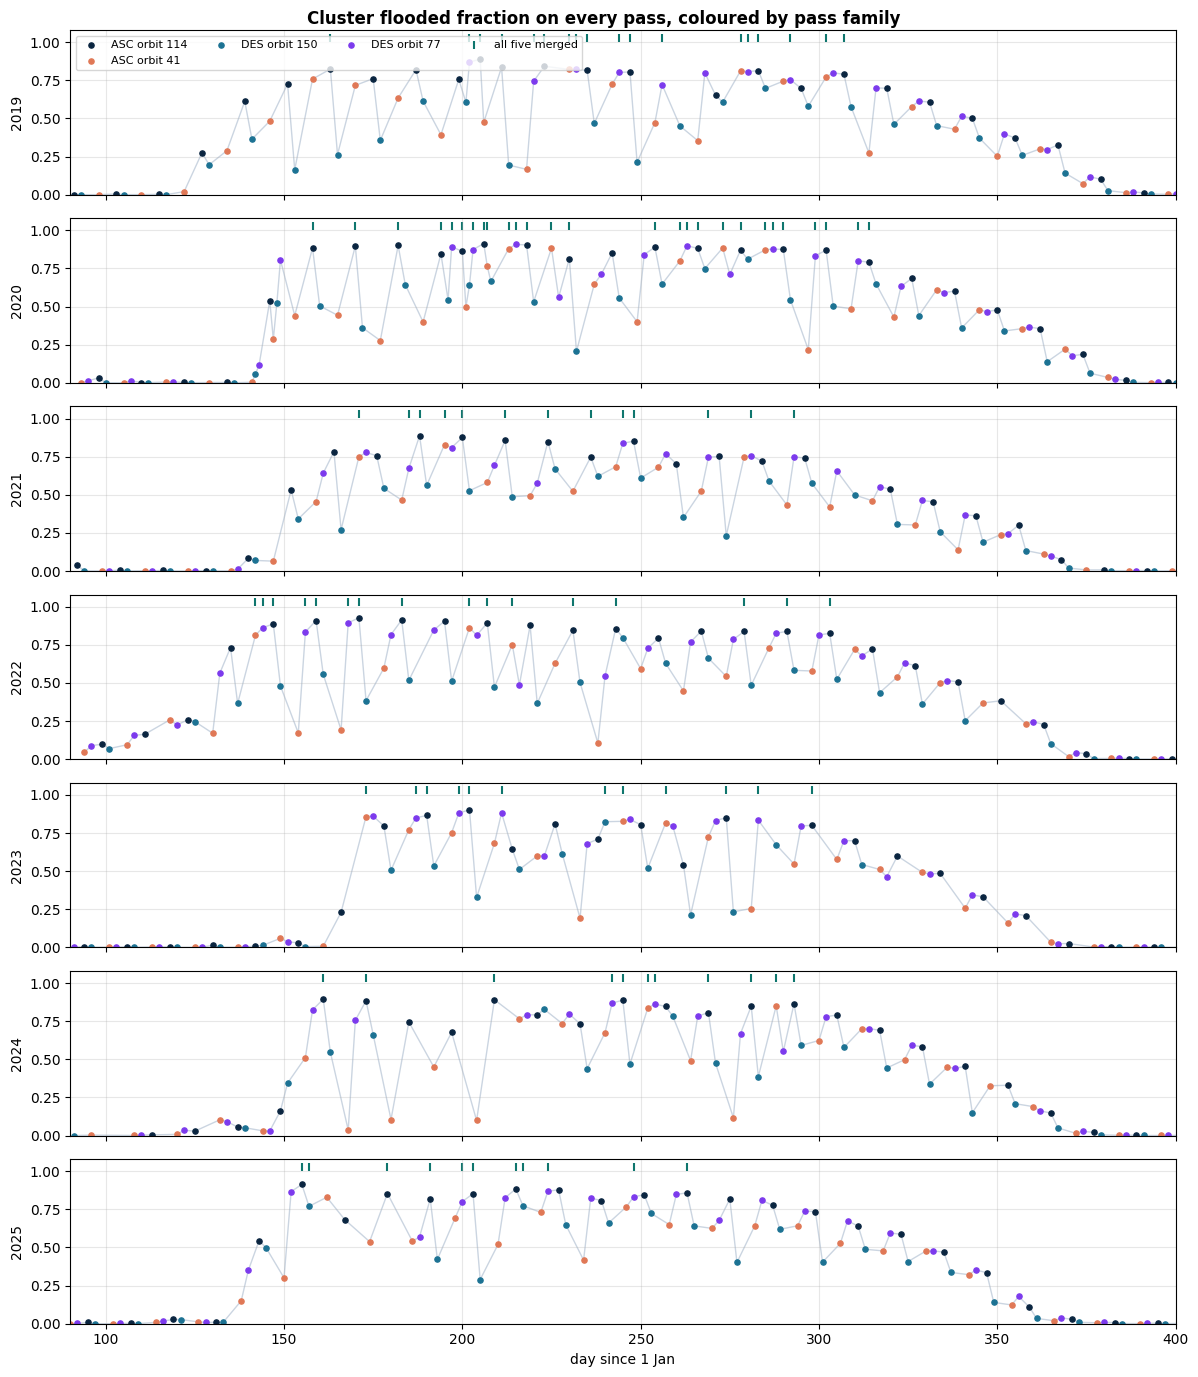

In [10]:
# ============ N9: TWO FAMILIES OF SENTINEL-1 PASSES SEE DIFFERENT AMOUNTS OF WATER ============
# Between passes only 2 to 5 days apart, the cluster flooded fraction jumps by
# 0.2 to 0.7 in the wet season, which water cannot do. The jumps follow the pass.
# On "dark-water" passes the open water reads -24 to -26 dB and its calmest parts
# fall below the -30 dB floor, which the production export MASKS, so obs_raw
# drops below 0.99 (on the dark-water dates checked, 97 to 99% of the masked
# pixels lie inside the haor cores, which are 79% of the study area).
# On "bright-water" passes the same water reads -16 to -19 dB, nothing is masked
# (obs_raw ~0.997) and much of it is missed. obs_raw is therefore a proxy for the
# pass family. Each family is most likely one relative orbit (one incidence
# angle). If s1_pass_catalog.csv from haor_s1_pass_catalog.py exists, this cell
# groups by the real relative orbit instead of the proxy.
# Pre-stated reading: if one family carries most of the merged dates, the merged
# count measures how often that geometry flew over, not how often water connected.
FAM_OBS = 0.99
fb = os.path.join(VAL, "sensitivity", "dates_baseline.csv")
if os.path.exists(fb):
    DB = pd.read_csv(fb)
    DB = DB[DB.n_components >= 0].copy()
    DB["family"] = np.where(DB.obs_raw >= FAM_OBS, "bright-water pass", "dark-water pass")
    if os.path.exists(CAT):
        cat = pd.read_csv(CAT)          # one row per scene: year, doy, relative_orbit, direction, inc_mean, ...
        # one row per stack date: several slices of one pass share a date; two orbits on one
        # UTC date (rare) were combined by the same-day maximum, so they are marked 'mixed'
        agg = cat.groupby(["year", "doy"]).agg(n_orbits=("relative_orbit", "nunique"),
                                               relative_orbit=("relative_orbit", "first"),
                                               direction=("direction", "first"),
                                               inc_mean=("inc_mean", "mean"),
                                               vv_perm_med=("vv_perm_med", "median")).reset_index()
        DB = DB.merge(agg, on=["year", "doy"], how="left")
        DB["family"] = np.where(DB.n_orbits > 1, "mixed",
                                DB.direction.astype(str).str[:3] + " orbit " + DB.relative_orbit.astype("Int64").astype(str))
        print("per family: median incidence angle and median VV over permanent water (dB)")
        print(DB.groupby("family")[["inc_mean", "vv_perm_med"]].median().round(1).to_string())
    W9 = DB[(DB.doy >= 150) & (DB.doy <= 330)]
    t9 = W9.groupby("family").agg(dates=("doy", "size"), median_flooded=("cluster_frac", "median"),
                                  merged_share=("all_connected", "mean"), merged_dates=("all_connected", "sum")).round(3)
    print("Wet season (days 150 to 330), all years:")
    print(t9.to_string())
    allm = DB[DB.all_connected == True]
    print(f"\nall merged dates: {len(allm)}; on each family: {allm.family.value_counts().to_dict()}")
    rows = []
    for y, g in W9.sort_values("doy").groupby("year"):
        d, f = g.doy.values, g.cluster_frac.values
        for k in range(1, len(d)):
            rows.append(dict(gap=d[k] - d[k - 1], jump=abs(f[k] - f[k - 1])))
    J = pd.DataFrame(rows)
    print(f"median jump in flooded fraction between consecutive passes <= 3 days apart: "
          f"{J[J.gap <= 3].jump.median():.2f} (n {int((J.gap <= 3).sum())})")
    SCORE.append(("merged dates independent of pass geometry", "merged share similar on both pass families, wet season",
                  " | ".join(f"{k}: {v:.0%}" for k, v in t9.merged_share.items())))
    fig, ax = plt.subplots(len(sorted(DB.year.unique())), 1, figsize=(12, 2.0 * DB.year.nunique()), sharex=True)
    pal = dict(zip(sorted(DB.family.unique()), ["#0A2540", "#E07856", "#1C7293", "#7C3AED", "#0F766E"]))
    for a, (y, g) in zip(np.atleast_1d(ax), DB.groupby("year")):
        g = g.sort_values("doy")
        a.plot(g.doy, g.cluster_frac, color="#CBD5E1", lw=1, zorder=1)
        for fam, q in g.groupby("family"):
            a.scatter(q.doy, q.cluster_frac, s=14, color=pal[fam], label=fam, zorder=2)
        m = g[g.all_connected == True]
        a.scatter(m.doy, np.full(len(m), 1.03), marker="|", s=40, color="#0F766E", label="all five merged")
        a.set_ylim(0, 1.08); a.set_xlim(90, 400); a.set_ylabel(str(y)); a.grid(alpha=.3)
    np.atleast_1d(ax)[0].legend(ncol=4, fontsize=8, loc="upper left")
    np.atleast_1d(ax)[-1].set_xlabel("day since 1 Jan")
    fig.suptitle("Cluster flooded fraction on every pass, coloured by pass family", fontweight="bold")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, "N9_pass_families.png"), dpi=150); plt.show()
else:
    print("validation/sensitivity/dates_baseline.csv not found; run haor_parameter_sensitivity.py first")

40 key dates with all three images; 19 with a clear Sentinel-2 composite
                   s2_water  s1_flag20  alg100_wet  vv_median_db  pixel_agreement
family                                                                           
bright-water pass     0.843      0.268       0.420       -18.015            0.477
dark-water pass       0.843      0.658       0.725       -24.500            0.798


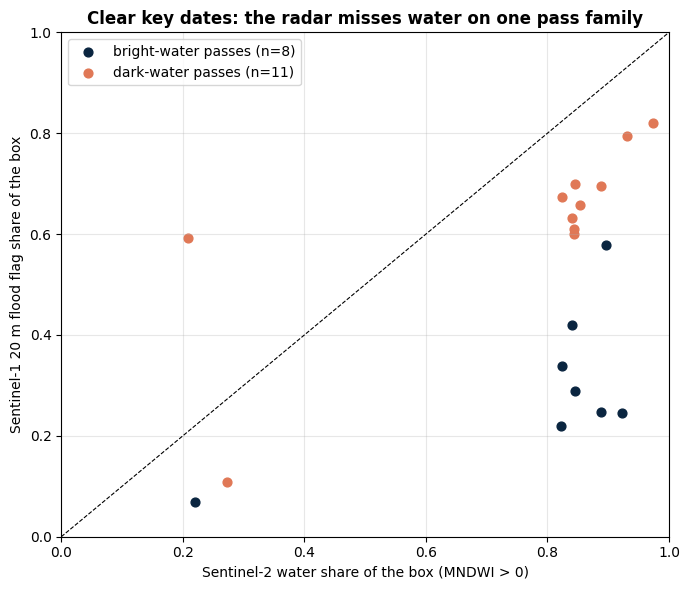

In [11]:
# ============ N10: SENTINEL-2 ON THE KEY DATES: WHICH PASS FAMILY IS RIGHT? ============
# For every key date with a Sentinel-2 composite (validation/images/*_S2_*.tif),
# water = MNDWI > 0 from green (B3) and SWIR (B11), inside a fixed box over the
# haor cores. Compared with the 20 m radar flood flag (same box, same date) and
# with the 100 m algorithm (all wet pixels, codes 2 to 4). Only composites with
# >= 90% clear pixels in the box are scored. MNDWI misses water under plants, so
# Sentinel-2 is a LOWER bound on water here.
from rasterio.windows import from_bounds
BOX = (91.0, 24.97, 91.25, 25.15)      # lon/lat box over the five haor cores
S2_CLEAR = 0.9
IMG = os.path.join(VAL, "images")
if os.path.isdir(IMG) and os.path.exists(KDF := os.path.join(VAL, "key_dates.csv")):
    K = pd.read_csv(KDF)
    rows = []
    for r in K.itertuples():
        ymd = r.date.replace("-", "")
        s2 = glob.glob(os.path.join(IMG, f"{r.label}_S2_{ymd}*.tif"))
        fl = glob.glob(os.path.join(IMG, f"{r.label}_FL20_{ymd}*.tif"))
        s1 = glob.glob(os.path.join(IMG, f"{r.label}_S1_{ymd}*.tif"))
        if not (s2 and fl and s1):
            continue
        with rasterio.open(s2[0]) as s:
            w = from_bounds(*BOX, s.transform)
            g = s.read(2, window=w).astype(float); sw = s.read(5, window=w).astype(float)   # B3, B11
        ok = (g > 0) & (sw > 0)
        mndwi = (g - sw) / (g + sw + 1e-9)
        with rasterio.open(fl[0]) as s:
            f = s.read(1, window=from_bounds(*BOX, s.transform)).astype(float)
        with rasterio.open(s1[0]) as s:
            v = s.read(1, window=from_bounds(*BOX, s.transform)).astype(float)
        w100 = np.nan
        cf = os.path.join(VIEWS[REF], f"codes_{r.year}.tif")
        if os.path.exists(cf):
            with rasterio.open(cf) as s:
                idx = {dayidx(d, r.year): i + 1 for i, d in enumerate(s.descriptions)}
                if r.doy in idx:
                    c = s.read(idx[r.doy], window=from_bounds(*BOX, s.transform))
                    cs = c[(c != C_OUT) & (c != C_SKIP)]
                    w100 = np.isin(cs, [C_WET, C_WETFILL, C_DROP]).mean() if cs.size else np.nan
        m = ok & (f != 255)
        obs = np.nan
        if os.path.exists(fb):
            q = DB[(DB.year == r.year) & (DB.doy == r.doy)]
            obs = float(q.obs_raw.iloc[0]) if len(q) else np.nan
        rows.append(dict(label=r.label, date=r.date, s2_clear=ok.mean(),
                         s2_water=(mndwi[ok] > 0).mean() if ok.any() else np.nan,
                         s1_flag20=(f[f != 255] == 1).mean(), alg100_wet=w100,
                         vv_median_db=np.median(v[v != -32768]) / 100,
                         pixel_agreement=((mndwi > 0) == (f == 1))[m].mean() if m.any() else np.nan,
                         family=("bright-water pass" if obs >= FAM_OBS else "dark-water pass") if np.isfinite(obs) else "?"))
    N10 = pd.DataFrame(rows)
    N10.to_csv(os.path.join(OUT, "N10_sentinel2_check.csv"), index=False)
    G = N10[N10.s2_clear >= S2_CLEAR]
    print(f"{len(N10)} key dates with all three images; {len(G)} with a clear Sentinel-2 composite")
    print(G.groupby("family")[["s2_water", "s1_flag20", "alg100_wet", "vv_median_db", "pixel_agreement"]].median().round(3).to_string())
    G = G.assign(miss=G.s2_water - G.s1_flag20)
    for fam, q in G.groupby("family"):
        SCORE.append((f"radar sees the water Sentinel-2 sees ({fam})", "median (S2 water - S1 20 m water) on clear key dates",
                      f"{q.miss.median():+.2f} of the box (n {len(q)})"))
    fig, ax = plt.subplots(figsize=(7, 6))
    for fam, c in [("bright-water pass", "#0A2540"), ("dark-water pass", "#E07856")]:
        q = G[G.family == fam]
        ax.scatter(q.s2_water, q.s1_flag20, s=40, c=c, label=f"{fam}es (n={len(q)})")
    ax.plot([0, 1], [0, 1], "k--", lw=.8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.legend()
    ax.set_xlabel("Sentinel-2 water share of the box (MNDWI > 0)")
    ax.set_ylabel("Sentinel-1 20 m flood flag share of the box")
    ax.set_title("Clear key dates: the radar misses water on one pass family", fontweight="bold")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, "N10_s2_vs_s1.png"), dpi=160); plt.show()
else:
    print("validation/images or key_dates.csv not found; skipped")

Wet season (days 150 to 330): median wet share of the cluster, by view and orbit family
family                  ASC orbit 114  ASC orbit 41  DES orbit 150  DES orbit 77
view                                                                            
100 m                           0.675         0.437          0.402         0.626
100 m by-orbit (clamp)          0.673         0.505          0.487         0.627
100 m by-orbit (mask)           0.662         0.505          0.487         0.627

median jump between passes 3 days or less apart (water cannot change this fast):
view
100 m                     0.151
100 m by-orbit (clamp)    0.103
100 m by-orbit (mask)     0.097

clear key dates: median (Sentinel-2 water - radar wet), by view and orbit family
family                  ASC orbit 114  ASC orbit 41  DES orbit 150  DES orbit 77
view                                                                            
100 m                           0.133         0.293          0.454         0.075

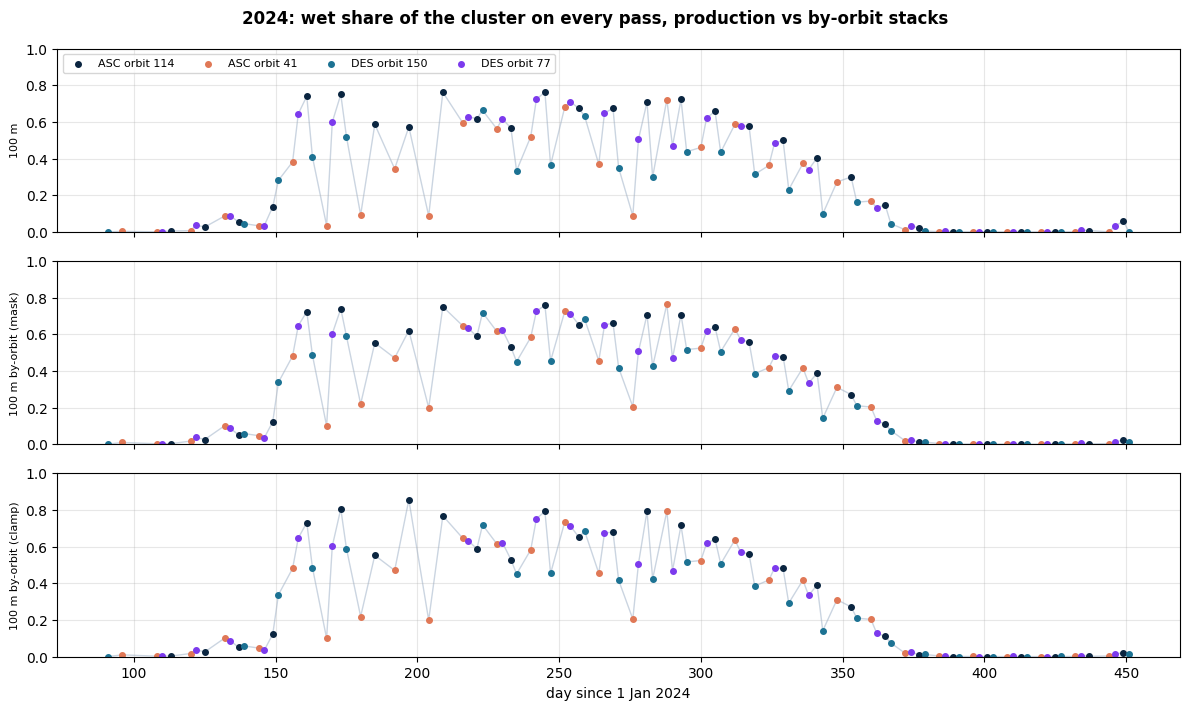

In [12]:
# ============ N11: DOES ONE BASELINE PER ORBIT FIX THE PASS-FAMILY GAP? ============
# Runs once the by-orbit stacks are labelled (step 4 of the doc) and the pass
# catalogue exists (step 2). For every radar view, the share of the cluster that
# is wet on each pass (codes 2 to 4, the same wet definition as N10), grouped
# by the orbit that flew the pass.
# Pre-stated rule: the by-orbit stack fixes the problem if, in the wet season,
#   (a) the median wet share of the two orbit families differs by 0.10 or less, and
#   (b) on clear key dates both families are within 0.10 of Sentinel-2 (median).
# If it passes, the main notebook should be pointed at that stack.
NEW = [v for v in VIEWS if "by-orbit" in v]
if not NEW:
    print("no by-orbit label folders yet (doc step 4); N11 skipped")
elif not os.path.exists(CAT):
    print("next_checks/s1_pass_catalog.csv not found (doc step 2); N11 needs it to name the orbits")
else:
    cat = pd.read_csv(CAT)
    fam = (cat.groupby(["year", "doy"])
              .agg(n_orb=("relative_orbit", "nunique"), orbit=("relative_orbit", "first"),
                   direction=("direction", "first")).reset_index())
    fam["family"] = np.where(fam.n_orb > 1, "mixed",
                             fam.direction.astype(str).str[:3] + " orbit " + fam.orbit.astype(str))
    fam = fam[["year", "doy", "family"]]

    def wet_shares(folder, box=None):
        """(year, doy) -> share of observed in-cluster pixels that are wet, from codes_<year>.tif."""
        rows = []
        for f in sorted(glob.glob(os.path.join(folder, "codes_*.tif"))):
            y = int(re.search(r"codes_(\d{4})", f).group(1))
            with rasterio.open(f) as s:
                win = from_bounds(*box, s.transform) if box else None
                for i, d in enumerate(s.descriptions):
                    c = s.read(i + 1, window=win)
                    cs = c[(c != C_OUT) & (c != C_SKIP)]
                    rows.append(dict(year=y, doy=dayidx(d, y),
                                     wet=np.isin(cs, [C_WET, C_WETFILL, C_DROP]).mean() if cs.size else np.nan))
        return pd.DataFrame(rows)

    from rasterio.windows import from_bounds
    res, s2rows = [], []
    for view in ["100 m"] + NEW:
        W = wet_shares(VIEWS[view]).merge(fam, on=["year", "doy"], how="left")
        W["view"] = view
        res.append(W)
        if os.path.exists(os.path.join(OUT, "N10_sentinel2_check.csv")):
            n10 = pd.read_csv(os.path.join(OUT, "N10_sentinel2_check.csv"))
            n10 = n10[n10.s2_clear >= S2_CLEAR].drop(columns=["family"], errors="ignore")
            kd = pd.read_csv(KDF)[["label", "year", "doy"]]
            n10 = n10.merge(kd, on="label")
            B = wet_shares(VIEWS[view], box=BOX).rename(columns={"wet": "radar_box"})
            q = n10.merge(B, on=["year", "doy"]).merge(fam, on=["year", "doy"], how="left")
            q["view"] = view
            s2rows.append(q)
    R = pd.concat(res)
    R.to_csv(os.path.join(OUT, "N11_wet_share_by_view.csv"), index=False)
    wet = R[(R.doy >= 150) & (R.doy <= 330)]
    t11 = wet.pivot_table(index="view", columns="family", values="wet", aggfunc="median").round(3)
    print("Wet season (days 150 to 330): median wet share of the cluster, by view and orbit family")
    print(t11.to_string())
    jumps = []
    for (view, y), g in wet.sort_values("doy").groupby(["view", "year"]):
        d, f = g.doy.values, g.wet.values
        jumps += [dict(view=view, jump=abs(f[k] - f[k - 1])) for k in range(1, len(d)) if d[k] - d[k - 1] <= 3]
    J11 = pd.DataFrame(jumps).groupby("view").jump.median().round(3)
    print("\nmedian jump between passes 3 days or less apart (water cannot change this fast):")
    print(J11.to_string())
    fams = [c for c in t11.columns if c != "mixed"]
    for view in t11.index:
        gap = t11.loc[view, fams].max() - t11.loc[view, fams].min()
        SCORE.append((f"N11 family gap, {view}", "wet-season median differs by <= 0.10 between orbits",
                      f"{gap:.2f}" + (" PASS" if gap <= 0.10 else " FAIL")))
    if s2rows:
        S = pd.concat(s2rows)
        S["miss"] = S.s2_water - S.radar_box
        S.to_csv(os.path.join(OUT, "N11_s2_by_view.csv"), index=False)
        t2 = S.pivot_table(index="view", columns="family", values="miss", aggfunc="median").round(3)
        if t2.empty:
            print("\nno clear Sentinel-2 key date matches these views; no Sentinel-2 comparison")
        else:
            print("\nclear key dates: median (Sentinel-2 water - radar wet), by view and orbit family")
            print(t2.to_string())
        for view in t2.index:
            worst = t2.loc[view].abs().max()
            SCORE.append((f"N11 against Sentinel-2, {view}", "every family within 0.10 of Sentinel-2 (median)",
                          f"worst {worst:.2f}" + (" PASS" if worst <= 0.10 else " FAIL")))
    yrs = [2024] if 2024 in set(R.year) else sorted(set(R.year))[-1:]
    views = ["100 m"] + NEW
    fig, ax = plt.subplots(len(views), 1, figsize=(12, 2.4 * len(views)), sharex=True, sharey=True)
    pal = dict(zip(sorted(R.family.dropna().unique()), ["#0A2540", "#E07856", "#1C7293", "#7C3AED", "#0F766E"]))
    for a, view in zip(np.atleast_1d(ax), views):
        g = R[(R.view == view) & (R.year == yrs[0])].sort_values("doy")
        a.plot(g.doy, g.wet, color="#CBD5E1", lw=1, zorder=1)
        for fm, q in g.groupby("family"):
            a.scatter(q.doy, q.wet, s=16, color=pal.get(fm, "grey"), label=fm, zorder=2)
        a.set_ylabel(view, fontsize=8); a.grid(alpha=.3); a.set_ylim(0, 1)
    np.atleast_1d(ax)[0].legend(ncol=4, fontsize=8, loc="upper left")
    np.atleast_1d(ax)[-1].set_xlabel(f"day since 1 Jan {yrs[0]}")
    fig.suptitle(f"{yrs[0]}: wet share of the cluster on every pass, production vs by-orbit stacks",
                 fontweight="bold")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, "N11_byorbit_vs_production.png"), dpi=150); plt.show()

In [13]:
# ============ N8: SCORECARD OF THE NEXT CHECKS ============
SC = pd.DataFrame(SCORE, columns=["check", "criterion", "result"])
pd.set_option("display.max_colwidth", 120)
print(SC.to_string(index=False))
SC.to_csv(os.path.join(OUT, "scorecard_next_checks.csv"), index=False)

# copy the small tables of the by-orbit label folders into next_checks/, so one
# folder holds everything (the large .tif files stay where they are)
import shutil
for view in [v for v in VIEWS if "by-orbit" in v]:
    dst = os.path.join(OUT, os.path.basename(VIEWS[view]))
    os.makedirs(dst, exist_ok=True)
    for f in glob.glob(os.path.join(VIEWS[view], "*.csv")) + glob.glob(os.path.join(VIEWS[view], "*.txt")):
        shutil.copy2(f, dst)
    print(f"copied the tables of {view} to {dst}")
print(f"\nrun finished {datetime.datetime.now():%Y-%m-%d %H:%M}. Download this folder for Claude: {OUT}")
_LOG.close()

                                                   check                                                                                    criterion                                                                                   result
                         30 m breaks are level barriers?                           median |step| on 100 m merged / 30 m separate passes > 2 x placebo                                                    NO (0.032 m vs placebo 0.019 m, n 35)
            SWOT coupling date matches radar first merge                               radar first merged date inside the SWOT spring bracket (+-3 d)                                                                        4 of 4 pair-years
           SWOT decoupling date matches radar last merge                                radar last merged date inside the SWOT autumn bracket (+-3 d)         0 of 6 pair-years; radar ends a median 24 days before SWOT's last one-level pass
                 opening removes much more w